<div dir="rtl" style="font-family: 'Vazirmatn', 'Tahoma', sans-serif; line-height: 1.9; text-align: justify;">

# پروژه یادگیری ماشین روی داده‌های کیفیت آب
## ارزیابی مدل‌های طبقه‌بندی برای پیش‌بینی قابل شرب بودن آب

در این نوت‌بوک، یک خط لوله کامل و قابل دفاع برای مسئله دودویی `Water Potability` ساخته شده است. ستون هدف `Potability` است؛ مقدار `1` به معنی آب قابل شرب و مقدار `0` به معنی آب غیرقابل شرب است.

نکته مهم این نسخه این است که **خود مدل‌های یادگیری ماشین از صفر و با NumPy/Pandas پیاده‌سازی شده‌اند** و از کلاس‌های آماده‌ای مثل `sklearn.linear_model.LogisticRegression`، `sklearn.svm.SVC`، `sklearn.ensemble.RandomForestClassifier` یا `sklearn.neural_network.MLPClassifier` استفاده نشده است. ابزارهایی که در این نوت‌بوک استفاده می‌شوند فقط برای محاسبات عددی، تحلیل داده و رسم نمودار هستند. بنابراین ایراد اصلی نسخه قبلی، یعنی import کردن مدل‌ها، در این نسخه وجود ندارد.

ساختار کار شامل شناخت داده، تحلیل اکتشافی، مدیریت داده‌های گمشده بدون نشت اطلاعات، مقیاس‌بندی مناسب، پیاده‌سازی مدل‌های الزامی و دو مدل امتیازی، اعتبارسنجی متقاطع، تنظیم پارامترها، ارزیابی نهایی، تحلیل خطاها و انتخاب مدل نهایی با معیارهای شفاف است.
</div>

In [1]:
# =========================
# 0. Imports and settings
# =========================
import os
import glob
import json
import time
import copy
import warnings
from pathlib import Path
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

TARGET_COLUMN = 'Potability'
TEST_SIZE = 0.20
CV_SPLITS = 3
THRESHOLD_GRID = np.round(np.arange(0.20, 0.81, 0.05), 2)
SAFETY_MAX_DANGEROUS_FP_RATE = 0.20
SAFETY_MIN_RECALL = 0.20

OUTPUT_DIR = Path('water_potability_final_outputs')
FIG_DIR = OUTPUT_DIR / 'figures'
TABLE_DIR = OUTPUT_DIR / 'tables'
TEXT_DIR = OUTPUT_DIR / 'text_outputs'

for folder in [OUTPUT_DIR, FIG_DIR, TABLE_DIR, TEXT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print('Project initialized successfully.')
print('Output directory:', OUTPUT_DIR.resolve())
print('Important note: all ML models below are implemented manually; no sklearn model class is imported.')

Project initialized successfully.
Output directory: /kaggle/working/water_potability_final_outputs
Important note: all ML models below are implemented manually; no sklearn model class is imported.


<div dir="rtl" style="font-family: 'Vazirmatn', 'Tahoma', sans-serif; line-height: 1.9; text-align: justify;">

## ۱. بارگذاری دیتاست

ابتدا فایل `water_potability.csv` خوانده می‌شود. مسیرها به گونه‌ای جست‌وجو می‌شوند که نوت‌بوک هم در Kaggle و هم در اجرای محلی قابل استفاده باشد. در این مرحله هیچ پیش‌پردازشی انجام نمی‌شود تا تحلیل اولیه داده‌ها بدون دستکاری باشد.
</div>

In [2]:
def find_csv_file(filename='water_potability.csv'):
    search_patterns = [
        filename,
        f'./{filename}',
        f'../input/**/{filename}',
        f'/kaggle/input/**/{filename}',
        f'/mnt/data/{filename}'
    ]
    for pattern in search_patterns:
        matches = glob.glob(pattern, recursive=True)
        if matches:
            return matches[0]
    raise FileNotFoundError(
        f'{filename} was not found. Please attach the Water Potability dataset in Kaggle or place it next to this notebook.'
    )

csv_path = find_csv_file('water_potability.csv')
df = pd.read_csv(csv_path)

print('CSV path:', csv_path)
print('Dataset shape:', df.shape)
display(df.head())


CSV path: ../input/datasets/evelin13/water-potability-2/water_potability.csv
Dataset shape: (3276, 10)


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


<div dir="rtl" style="font-family: 'Vazirmatn', 'Tahoma', sans-serif; line-height: 1.9; text-align: justify;">

## ۲. شناخت اولیه داده‌ها

داده‌ها شامل ۹ ویژگی شیمیایی و فیزیکی آب و یک ستون هدف هستند. در این بخش نوع ستون‌ها، آمار توصیفی و توزیع کلاس هدف بررسی می‌شود. چون کلاس‌ها کاملاً متوازن نیستند، از همین ابتدا مشخص است که `Accuracy` به تنهایی معیار کافی نیست و باید معیارهایی مثل `F1`، `Balanced Accuracy` و نوع خطاها هم تحلیل شوند.
</div>

Columns:
['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity', 'Potability']

Data types:


,dtype
ph,float64
Hardness,float64
Solids,float64
Chloramines,float64
Sulfate,float64
Conductivity,float64
Organic_carbon,float64
Trihalomethanes,float64
Turbidity,float64
Potability,int64


,count,mean,std,min,25%,50%,75%,max
ph,2785.0,7.0808,1.5943,0.0000,6.0931,7.0368,8.0621,14.0000
Hardness,3276.0,196.3695,32.8798,47.4320,176.8505,196.9676,216.6675,323.1240
Solids,3276.0,22014.0925,8768.5708,320.9426,15666.6903,20927.8336,27332.7621,61227.1960
Chloramines,3276.0,7.1223,1.5831,0.3520,6.1274,7.1303,8.1149,13.1270
Sulfate,2495.0,333.7758,41.4168,129.0000,307.6995,333.0735,359.9502,481.0306
Conductivity,3276.0,426.2051,80.8241,181.4838,365.7344,421.8850,481.7923,753.3426
Organic_carbon,3276.0,14.2850,3.3082,2.2000,12.0658,14.2183,16.5577,28.3000
Trihalomethanes,3114.0,66.3963,16.1750,0.7380,55.8445,66.6225,77.3375,124.0000
Turbidity,3276.0,3.9668,0.7804,1.4500,3.4397,3.9550,4.5003,6.7390
Potability,3276.0,0.3901,0.4878,0.0000,0.0000,0.0000,1.0000,1.0000


,class,count,percentage,class_label
0,0,1998,0.60989,Not Potable
1,1,1278,0.39011,Potable


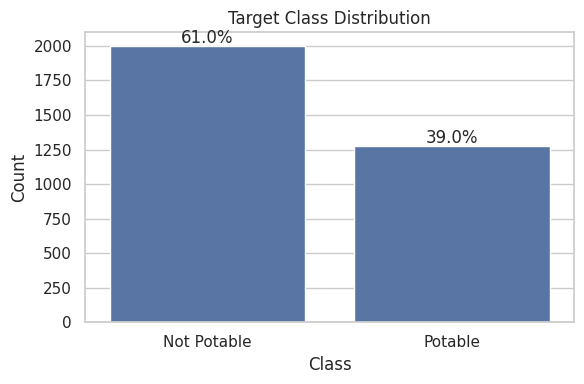

In [3]:
feature_columns = [col for col in df.columns if col != TARGET_COLUMN]

print('Columns:')
print(list(df.columns))
print('\nData types:')
display(df.dtypes.to_frame('dtype'))

stats = df.describe().T
stats.to_csv(TABLE_DIR / 'descriptive_statistics.csv')
display(stats.round(4))

target_summary = (
    df[TARGET_COLUMN]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis('class')
    .reset_index(name='count')
)
target_summary['percentage'] = target_summary['count'] / target_summary['count'].sum()
target_summary['class_label'] = target_summary['class'].map({0: 'Not Potable', 1: 'Potable'})
target_summary.to_csv(TABLE_DIR / 'target_distribution.csv', index=False)

display(target_summary)

plt.figure(figsize=(6, 4))
sns.barplot(data=target_summary, x='class_label', y='count', color='C0')
plt.title('Target Class Distribution')
plt.xlabel('Class')
plt.ylabel('Count')
for idx, row in target_summary.iterrows():
    plt.text(idx, row['count'] + max(target_summary['count']) * 0.01, f"{row['percentage']:.1%}", ha='center')
plt.tight_layout()
plt.savefig(FIG_DIR / '01_target_distribution.png', dpi=200, bbox_inches='tight')
plt.show()


<div dir="rtl" style="font-family: 'Vazirmatn', 'Tahoma', sans-serif; line-height: 1.9; text-align: justify;">

### تحلیل اولیه کلاس هدف

اگر یک مدل همیشه کلاس اکثریت را پیش‌بینی کند، به یک `baseline` ساده می‌رسد. بنابراین در انتهای پروژه، عملکرد مدل نهایی با این baseline مقایسه می‌شود تا روشن باشد که مدل واقعاً چه مقدار ارزش افزوده ایجاد کرده است. این نکته از ایرادهای نسخه قبلی بود و در این نسخه صریحاً بررسی می‌شود.
</div>

In [4]:
majority_class = int(df[TARGET_COLUMN].mode().iloc[0])
majority_baseline_accuracy = (df[TARGET_COLUMN] == majority_class).mean()
print('Majority class:', majority_class)
print('Majority baseline accuracy:', round(float(majority_baseline_accuracy), 4))


Majority class: 0
Majority baseline accuracy: 0.6099


<div dir="rtl" style="font-family: 'Vazirmatn', 'Tahoma', sans-serif; line-height: 1.9; text-align: justify;">

## ۳. بررسی داده‌های گمشده

داده‌های گمشده ابتدا فقط گزارش می‌شوند. پر کردن آن‌ها در همین مرحله انجام نمی‌شود، چون اگر قبل از تقسیم آموزش/آزمون Imputation انجام شود، اطلاعات آزمون وارد فرآیند آموزش می‌شود. در این نوت‌بوک، Imputer دستی فقط روی داده آموزش fit می‌شود و سپس روی validation/test اعمال می‌شود.
</div>

,feature,missing_count,missing_percentage
4,Sulfate,781,23.840049
0,ph,491,14.987790
7,Trihalomethanes,162,4.945055
1,Hardness,0,0.000000
3,Chloramines,0,0.000000
2,Solids,0,0.000000
5,Conductivity,0,0.000000
6,Organic_carbon,0,0.000000
8,Turbidity,0,0.000000
9,Potability,0,0.000000


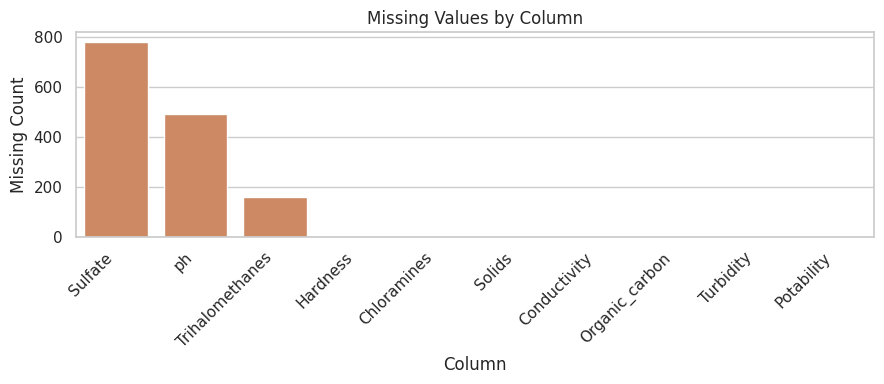

In [5]:
missing_df = pd.DataFrame({
    'feature': df.columns,
    'missing_count': df.isna().sum().values,
    'missing_percentage': df.isna().mean().values * 100
}).sort_values('missing_count', ascending=False)

missing_df.to_csv(TABLE_DIR / 'missing_values.csv', index=False)
display(missing_df)

plt.figure(figsize=(9, 4))
sns.barplot(data=missing_df, x='feature', y='missing_count', color='C1')
plt.title('Missing Values by Column')
plt.xlabel('Column')
plt.ylabel('Missing Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(FIG_DIR / '02_missing_values.png', dpi=200, bbox_inches='tight')
plt.show()


<div dir="rtl" style="font-family: 'Vazirmatn', 'Tahoma', sans-serif; line-height: 1.9; text-align: justify;">

## ۴. تحلیل اکتشافی داده‌ها

توزیع ویژگی‌ها با Histogram و مقدارهای پرت با Boxplot بررسی می‌شود. مقدارهای پرت حذف نمی‌شوند، چون در مسئله کیفیت آب، مقدارهای غیرعادی می‌توانند نشانه وضعیت واقعی مثل آلودگی یا شرایط خاص منبع آب باشند. حذف کورکورانه آن‌ها ممکن است بخشی از اطلاعات مهم را از بین ببرد.
</div>

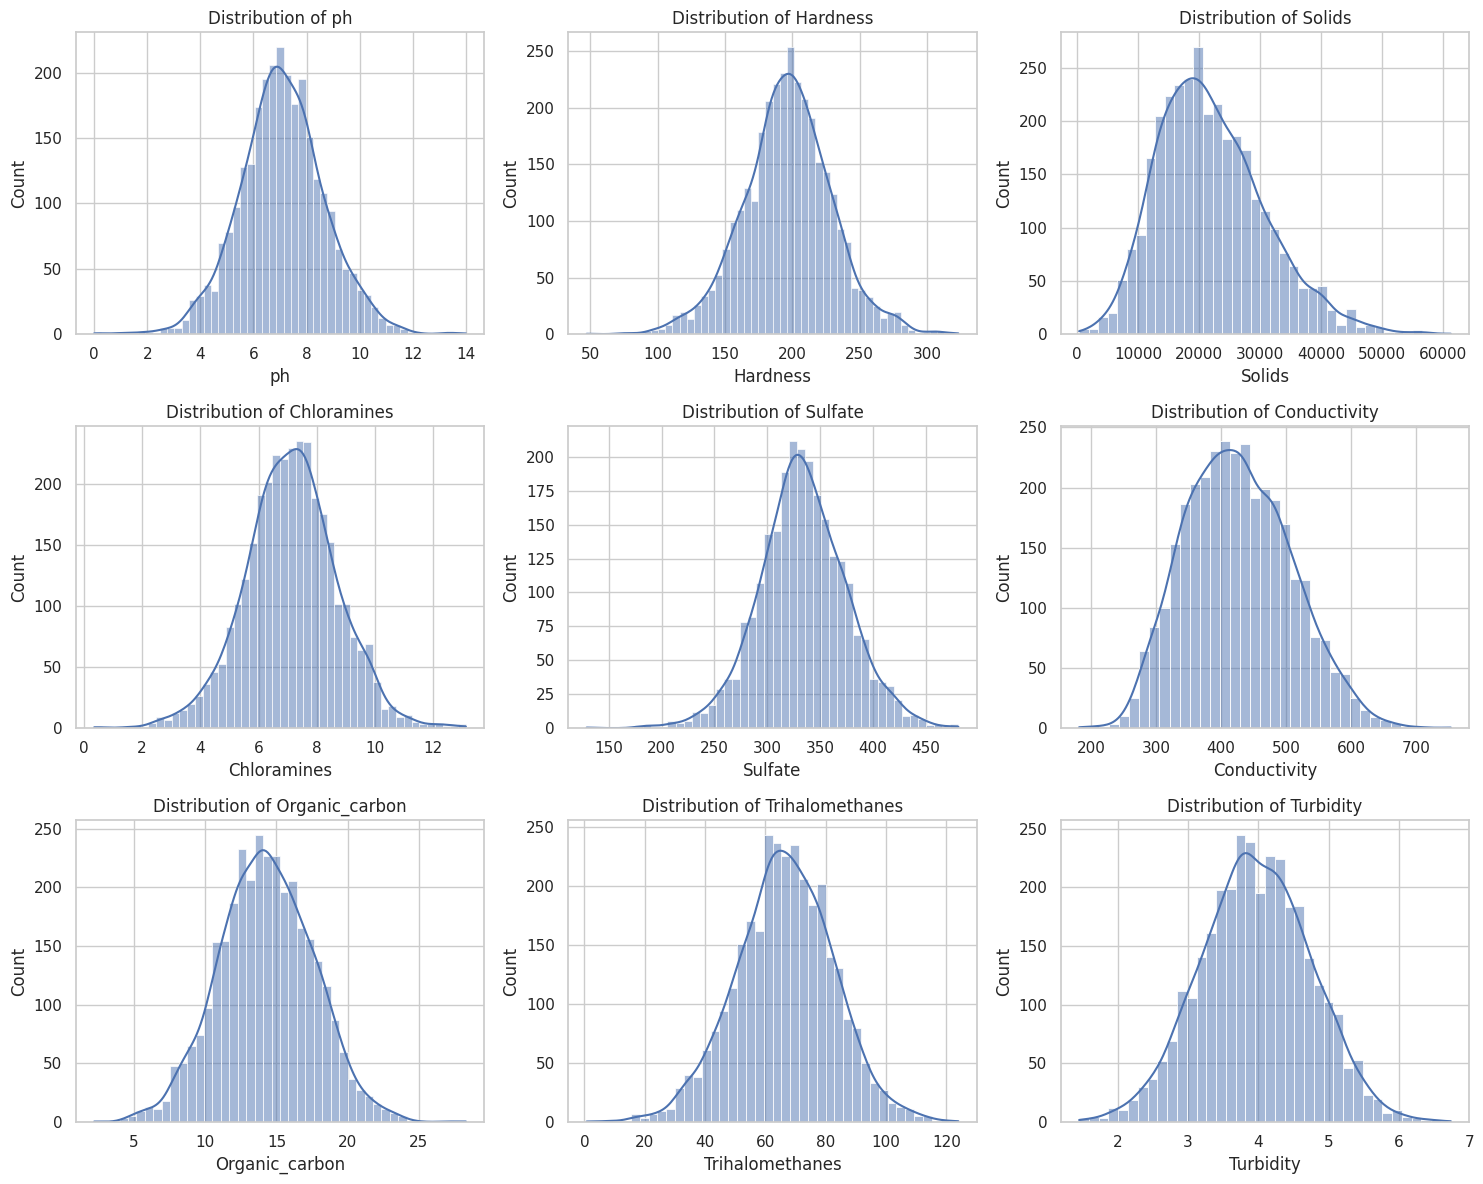

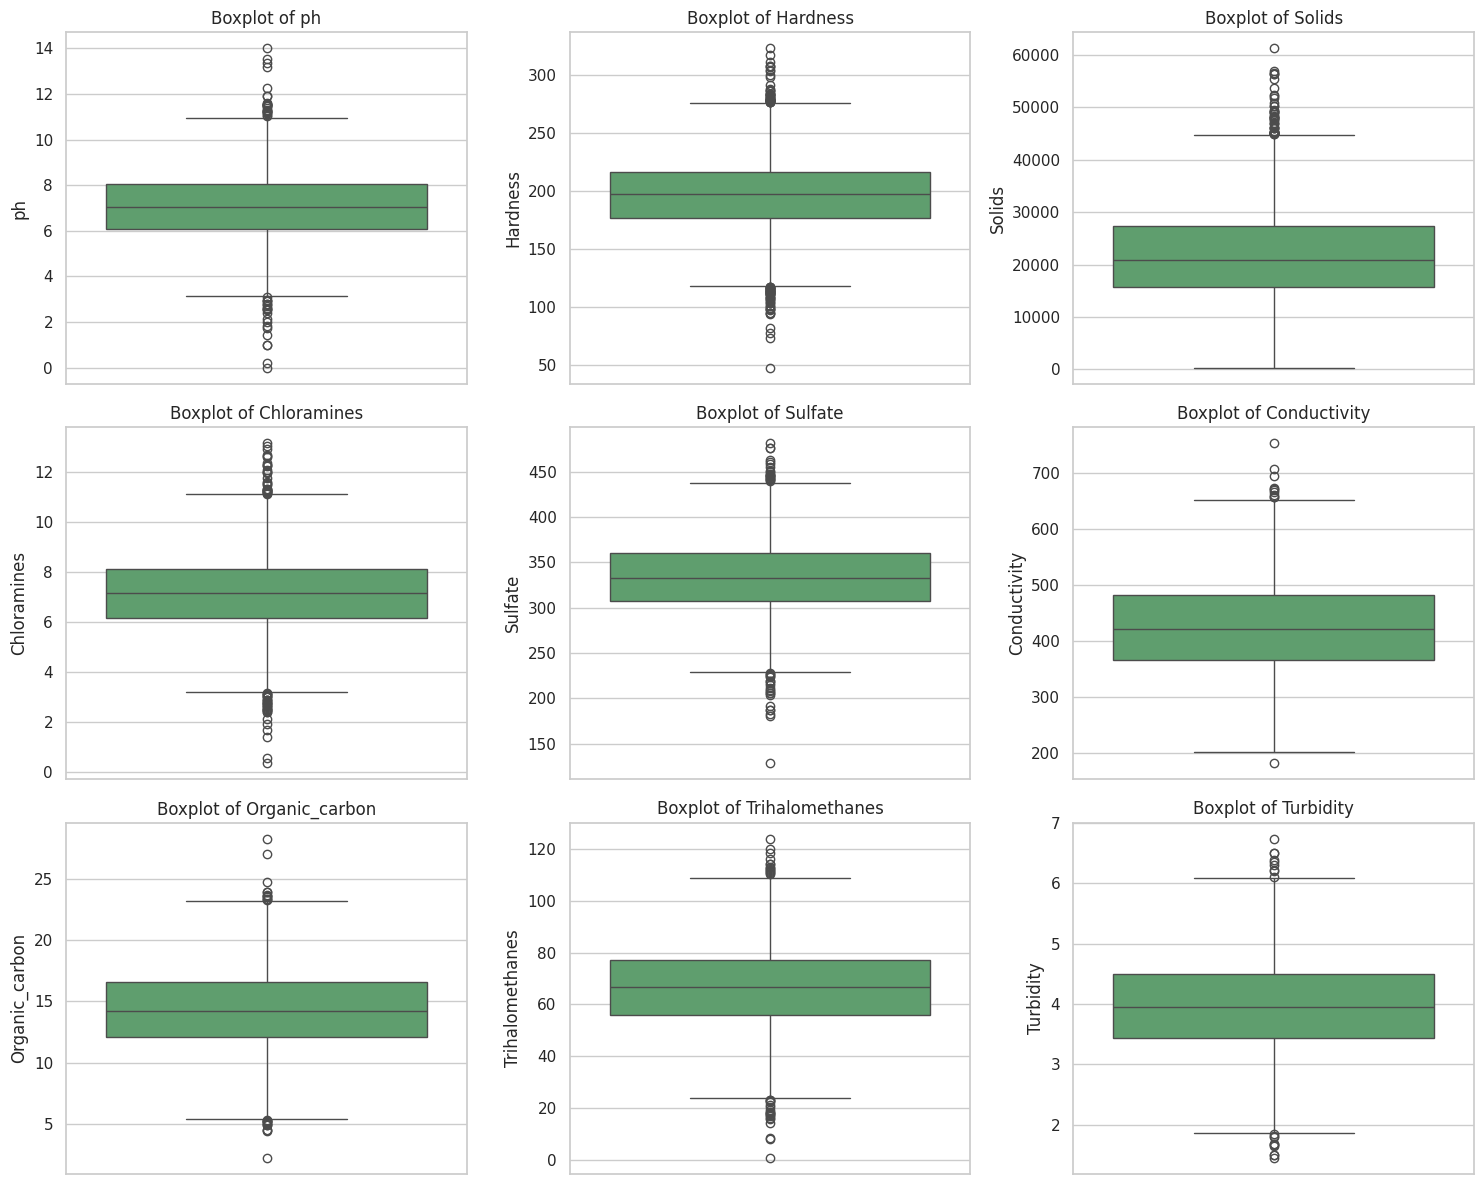

,feature,q1,q3,iqr,lower_bound,upper_bound,outlier_count,outlier_percentage
0,ph,6.0931,8.0621,1.9690,3.1396,11.0155,46,1.6517
1,Hardness,176.8505,216.6675,39.8169,117.1252,276.3928,83,2.5336
2,Solids,15666.6903,27332.7621,11666.0718,-1832.4174,44831.8699,47,1.4347
3,Chloramines,6.1274,8.1149,1.9875,3.1462,11.0961,61,1.8620
4,Sulfate,307.6995,359.9502,52.2507,229.3235,438.3262,41,1.6433
5,Conductivity,365.7344,481.7923,116.0579,191.6476,655.8791,11,0.3358
6,Organic_carbon,12.0658,16.5577,4.4919,5.3280,23.2954,25,0.7631
7,Trihalomethanes,55.8445,77.3375,21.4929,23.6051,109.5769,33,1.0597
8,Turbidity,3.4397,4.5003,1.0606,1.8488,6.0912,19,0.5800


In [6]:
n_features = len(feature_columns)
n_cols = 3
n_rows = int(np.ceil(n_features / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.flatten()
for i, col in enumerate(feature_columns):
    sns.histplot(df[col], kde=True, ax=axes[i], color='C0')
    axes[i].set_title(f'Distribution of {col}')
for j in range(i + 1, len(axes)):
    axes[j].axis('off')
plt.tight_layout()
plt.savefig(FIG_DIR / '03_feature_histograms.png', dpi=200, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.flatten()
for i, col in enumerate(feature_columns):
    sns.boxplot(y=df[col], ax=axes[i], color='C2')
    axes[i].set_title(f'Boxplot of {col}')
for j in range(i + 1, len(axes)):
    axes[j].axis('off')
plt.tight_layout()
plt.savefig(FIG_DIR / '04_feature_boxplots.png', dpi=200, bbox_inches='tight')
plt.show()

def build_outlier_summary(data, columns):
    rows = []
    for col in columns:
        series = data[col].dropna()
        q1 = series.quantile(0.25)
        q3 = series.quantile(0.75)
        iqr = q3 - q1
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        count = int(((series < lower) | (series > upper)).sum())
        rows.append({
            'feature': col,
            'q1': q1,
            'q3': q3,
            'iqr': iqr,
            'lower_bound': lower,
            'upper_bound': upper,
            'outlier_count': count,
            'outlier_percentage': count / len(series) * 100
        })
    return pd.DataFrame(rows)

outlier_summary = build_outlier_summary(df, feature_columns)
outlier_summary.to_csv(TABLE_DIR / 'outlier_summary.csv', index=False)
display(outlier_summary.round(4))


<div dir="rtl" style="font-family: 'Vazirmatn', 'Tahoma', sans-serif; line-height: 1.9; text-align: justify;">

## ۵. تحلیل همبستگی

ماتریس همبستگی نشان می‌دهد روابط خطی بین ویژگی‌ها و ستون هدف چقدر قوی هستند. اگر همبستگی مستقیم با هدف ضعیف باشد، انتظار داریم مدل‌های خطی ساده به تنهایی کافی نباشند و مدل‌های غیرخطی یا Ensemble شانس بهتری داشته باشند.
</div>

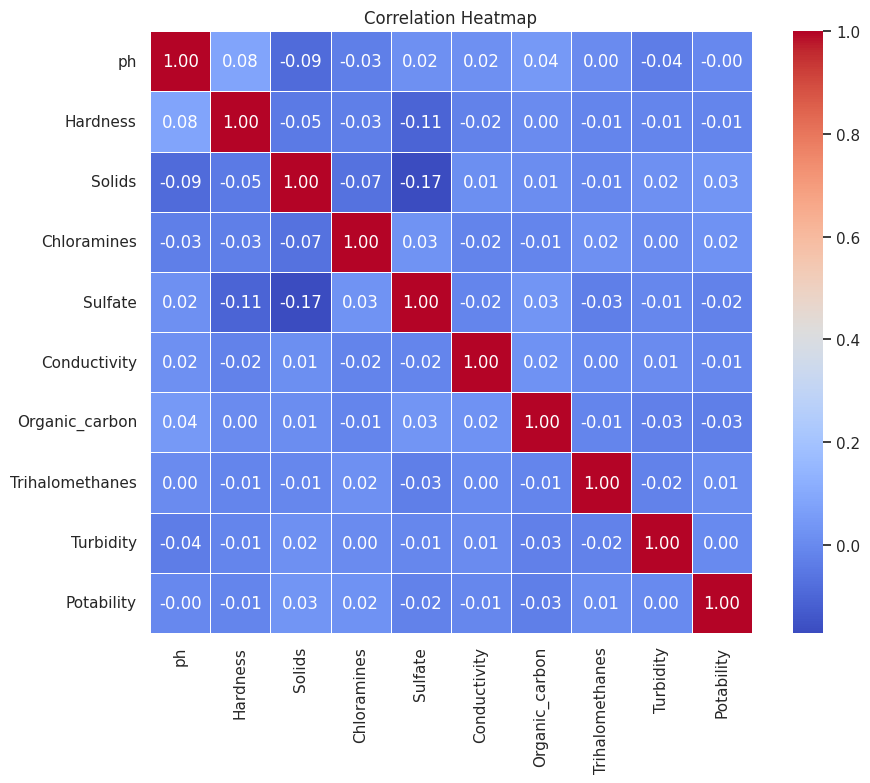

,feature,correlation_with_potability
0,Solids,0.0337
1,Organic_carbon,-0.0300
2,Chloramines,0.0238
3,Sulfate,-0.0236
4,Hardness,-0.0138
5,Conductivity,-0.0081
6,Trihalomethanes,0.0071
7,ph,-0.0036
8,Turbidity,0.0016


ph                  Hardness                         Solids  \
              mean  median     std      mean    median      std        mean   
Potability                                                                    
0           7.0854  7.0355  1.6835  196.7333  197.1234  31.0575  21777.4908   
1           7.0738  7.0368  1.4480  195.8007  196.6329  35.5470  22383.9910   

                                  Chloramines  ... Conductivity  \
                median        std        mean  ...          std   
Potability                                     ...                
0           20809.6183  8543.0688      7.0922  ...      80.0473   
1           21199.3866  9101.0102      7.1693  ...      82.0484   

           Organic_carbon                  Trihalomethanes                    \
                     mean   median     std            mean   median      std   
Potability                                                                     
0                 14.3643  14.2935  3.3346         66.3036  66.5422  16.0793   
1                 14.1609  14.1628  3.2639         66.5397  66.6782  16.3274   

           Turbidity                  
                mean  median     std  
Potability                            
0             3.9658  3.9481  0.7803  
1             3.9683  3.9586  0.7808  

[2 rows x 27 columns]

In [7]:
correlation_matrix = df.corr(numeric_only=True)
correlation_matrix.to_csv(TABLE_DIR / 'correlation_matrix.csv')

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', square=True, linewidths=0.5)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.savefig(FIG_DIR / '05_correlation_heatmap.png', dpi=200, bbox_inches='tight')
plt.show()

corr_target = (
    correlation_matrix[TARGET_COLUMN]
    .drop(TARGET_COLUMN)
    .sort_values(key=lambda s: s.abs(), ascending=False)
    .reset_index()
)
corr_target.columns = ['feature', 'correlation_with_potability']
corr_target.to_csv(TABLE_DIR / 'correlation_with_target.csv', index=False)
display(corr_target.round(4))

classwise_stats = df.groupby(TARGET_COLUMN)[feature_columns].agg(['mean', 'median', 'std'])
classwise_stats.to_csv(TABLE_DIR / 'classwise_statistics.csv')
display(classwise_stats.round(4))


<div dir="rtl" style="font-family: 'Vazirmatn', 'Tahoma', sans-serif; line-height: 1.9; text-align: justify;">

## ۶. تقسیم داده و پیش‌پردازش بدون نشت اطلاعات

در این بخش تقسیم داده به صورت `Stratified` و با نسبت ۸۰/۲۰ انجام می‌شود. سپس یک کلاس پیش‌پردازش دستی تعریف می‌شود که سه کار را انجام می‌دهد: ساخت ویژگی‌های کمکی، جایگزینی مقدارهای گمشده با میانه آموزش، و در صورت نیاز استانداردسازی با میانگین و انحراف معیار آموزش. این طراحی نقش Pipeline را دارد، اما کاملاً دستی نوشته شده است.
</div>

In [8]:
def stratified_train_test_split(X, y, test_size=0.2, random_state=42):
    rng = np.random.default_rng(random_state)
    y_array = np.asarray(y)
    train_indices = []
    test_indices = []
    for cls in np.unique(y_array):
        cls_indices = np.where(y_array == cls)[0]
        rng.shuffle(cls_indices)
        n_test = int(round(len(cls_indices) * test_size))
        test_indices.extend(cls_indices[:n_test])
        train_indices.extend(cls_indices[n_test:])
    train_indices = np.array(train_indices)
    test_indices = np.array(test_indices)
    rng.shuffle(train_indices)
    rng.shuffle(test_indices)
    return X.iloc[train_indices].reset_index(drop=True), X.iloc[test_indices].reset_index(drop=True), pd.Series(y_array[train_indices]), pd.Series(y_array[test_indices])

X = df.drop(columns=[TARGET_COLUMN])
y = df[TARGET_COLUMN].astype(int)

X_train, X_test, y_train, y_test = stratified_train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

split_distribution = pd.DataFrame({
    'set': ['train', 'train', 'test', 'test'],
    'class': [0, 1, 0, 1],
    'count': [
        int((y_train == 0).sum()), int((y_train == 1).sum()),
        int((y_test == 0).sum()), int((y_test == 1).sum())
    ]
})
split_distribution['percentage_in_set'] = split_distribution.groupby('set')['count'].transform(lambda s: s / s.sum())
split_distribution.to_csv(TABLE_DIR / 'train_test_distribution.csv', index=False)

display(split_distribution)
print('Train shape:', X_train.shape)
print('Test shape:', X_test.shape)


,set,class,count,percentage_in_set
0,train,0,1598,0.609924
1,train,1,1022,0.390076
2,test,0,400,0.609756
3,test,1,256,0.390244


Train shape: (2620, 9)
Test shape: (656, 9)


In [9]:
class WaterPreprocessor:
    # Manual preprocessing pipeline: feature engineering -> median imputation -> optional standard scaling.
    def __init__(self, scale=True, add_missing_indicators=True, add_domain_features=True):
        self.scale = scale
        self.add_missing_indicators = add_missing_indicators
        self.add_domain_features = add_domain_features

    def _engineer_features(self, X):
        X_df = pd.DataFrame(X).copy()
        X_df = X_df.astype(float)
        Z = X_df.copy()

        if self.add_missing_indicators:
            for col in X_df.columns:
                Z[f'{col}_missing'] = X_df[col].isna().astype(float)

        if self.add_domain_features:
            eps = 1e-9
            if 'ph' in X_df.columns:
                Z['ph_distance_from_neutral'] = (X_df['ph'] - 7.0).abs()
                Z['ph_in_who_range'] = ((X_df['ph'] >= 6.5) & (X_df['ph'] <= 8.5)).astype(float)
            if {'Solids', 'Conductivity'}.issubset(X_df.columns):
                Z['solids_to_conductivity'] = X_df['Solids'] / (X_df['Conductivity'] + eps)
            if {'Hardness', 'Sulfate', 'Solids', 'Conductivity'}.issubset(X_df.columns):
                Z['mineral_load_index'] = (
                    X_df['Hardness'] + X_df['Sulfate'] + X_df['Solids'] / 1000.0 + X_df['Conductivity']
                ) / 4.0
            if {'Chloramines', 'Trihalomethanes'}.issubset(X_df.columns):
                Z['disinfection_byproduct_index'] = X_df['Chloramines'] * X_df['Trihalomethanes']
            if {'Organic_carbon', 'Turbidity'}.issubset(X_df.columns):
                Z['organic_turbidity_index'] = X_df['Organic_carbon'] * X_df['Turbidity']
        return Z

    def fit(self, X, y=None):
        Z = self._engineer_features(X)
        self.feature_names_ = list(Z.columns)
        self.medians_ = Z.median(axis=0, skipna=True).fillna(0.0)
        Z_imputed = Z.fillna(self.medians_)
        self.means_ = Z_imputed.mean(axis=0)
        self.stds_ = Z_imputed.std(axis=0).replace(0, 1.0).fillna(1.0)
        return self

    def transform(self, X):
        Z = self._engineer_features(X)
        for col in self.feature_names_:
            if col not in Z.columns:
                Z[col] = np.nan
        Z = Z[self.feature_names_]
        Z = Z.fillna(self.medians_)
        if self.scale:
            Z = (Z - self.means_) / self.stds_
        return Z.to_numpy(dtype=float)

    def fit_transform(self, X, y=None):
        return self.fit(X, y).transform(X)

preprocessor_preview = WaterPreprocessor(scale=True).fit(X_train)
print('Original feature count:', X_train.shape[1])
print('Engineered feature count:', len(preprocessor_preview.feature_names_))
display(pd.DataFrame({'engineered_features': preprocessor_preview.feature_names_}).head(30))


Original feature count: 9
Engineered feature count: 24


,engineered_features
0,ph
1,Hardness
2,Solids
3,Chloramines
4,Sulfate
5,Conductivity
6,Organic_carbon
7,Trihalomethanes
8,Turbidity
9,ph_missing


<div dir="rtl" style="font-family: 'Vazirmatn', 'Tahoma', sans-serif; line-height: 1.9; text-align: justify;">

## ۷. توابع ارزیابی و ابزارهای کمکی

در این قسمت معیارهای ارزیابی نیز دستی محاسبه می‌شوند تا نوت‌بوک به کتابخانه‌های آماده مدل‌سازی وابسته نباشد. معیار `Dangerous FP Rate` برابر است با نسبت نمونه‌های غیرقابل شرب که اشتباهاً قابل شرب پیش‌بینی شده‌اند؛ یعنی `FP / (TN + FP)`. در این مسئله این خطا از نظر ایمنی بسیار مهم است.
</div>

In [10]:
def sigmoid(z):
    z = np.clip(z, -60, 60)
    return 1.0 / (1.0 + np.exp(-z))

def parameter_grid(grid):
    if not grid:
        return [{}]
    keys = list(grid.keys())
    values = [grid[k] for k in keys]
    return [dict(zip(keys, combination)) for combination in product(*values)]

def confusion_values(y_true, y_pred):
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)
    tn = int(((y_true == 0) & (y_pred == 0)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())
    fn = int(((y_true == 1) & (y_pred == 0)).sum())
    tp = int(((y_true == 1) & (y_pred == 1)).sum())
    return tn, fp, fn, tp

def binary_metrics(y_true, y_pred, scores=None):
    tn, fp, fn, tp = confusion_values(y_true, y_pred)
    accuracy = (tp + tn) / max(tp + tn + fp + fn, 1)
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    specificity = tn / max(tn + fp, 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-12)
    balanced_accuracy = 0.5 * (recall + specificity)
    dangerous_fp_rate = fp / max(tn + fp, 1)
    return {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'balanced_accuracy': balanced_accuracy,
        'specificity': specificity,
        'dangerous_fp_rate': dangerous_fp_rate,
        'tn': tn, 'fp': fp, 'fn': fn, 'tp': tp,
        'roc_auc': roc_auc_binary(y_true, scores) if scores is not None else np.nan,
        'average_precision': average_precision_binary(y_true, scores) if scores is not None else np.nan
    }

def rankdata_average_ties(a):
    a = np.asarray(a)
    order = np.argsort(a)
    ranks = np.empty(len(a), dtype=float)
    sorted_a = a[order]
    i = 0
    while i < len(a):
        j = i + 1
        while j < len(a) and sorted_a[j] == sorted_a[i]:
            j += 1
        avg_rank = (i + 1 + j) / 2.0
        ranks[order[i:j]] = avg_rank
        i = j
    return ranks

def roc_auc_binary(y_true, scores):
    y_true = np.asarray(y_true).astype(int)
    scores = np.asarray(scores, dtype=float)
    n_pos = (y_true == 1).sum()
    n_neg = (y_true == 0).sum()
    if n_pos == 0 or n_neg == 0:
        return np.nan
    ranks = rankdata_average_ties(scores)
    sum_pos_ranks = ranks[y_true == 1].sum()
    auc = (sum_pos_ranks - n_pos * (n_pos + 1) / 2.0) / (n_pos * n_neg)
    return float(auc)

def average_precision_binary(y_true, scores):
    y_true = np.asarray(y_true).astype(int)
    scores = np.asarray(scores, dtype=float)
    n_pos = (y_true == 1).sum()
    if n_pos == 0:
        return np.nan
    order = np.argsort(-scores)
    y_sorted = y_true[order]
    tp_cumsum = np.cumsum(y_sorted == 1)
    precision_at_k = tp_cumsum / (np.arange(len(y_sorted)) + 1)
    return float((precision_at_k * (y_sorted == 1)).sum() / n_pos)

def get_scores(model, X):
    if hasattr(model, 'predict_proba'):
        return model.predict_proba(X)[:, 1]
    if hasattr(model, 'decision_function'):
        raw = model.decision_function(X)
        return sigmoid(raw)
    return model.predict(X)

def predict_from_scores(scores, threshold=0.5):
    return (np.asarray(scores, dtype=float) >= float(threshold)).astype(int)

def evaluate_thresholds(y_true, scores, thresholds=THRESHOLD_GRID):
    rows = []
    for threshold in thresholds:
        y_pred = predict_from_scores(scores, threshold)
        m = binary_metrics(y_true, y_pred, scores)
        row = {'threshold': float(threshold)}
        row.update(m)
        rows.append(row)
    return pd.DataFrame(rows)

def choose_threshold_by_validation(y_true, scores, thresholds=THRESHOLD_GRID,
                                   max_dangerous_fp_rate=SAFETY_MAX_DANGEROUS_FP_RATE,
                                   min_recall=SAFETY_MIN_RECALL):
    """Choose a threshold only from validation data.

    The rule is deliberately transparent and non-test-based:
    1. Prefer thresholds satisfying the safety constraints.
    2. Among those, maximize validation F1, then Balanced Accuracy, then minimize Dangerous FP Rate.
    3. If no threshold satisfies the constraints, fall back to the highest validation F1 and report that the
       safety constraint was not satisfied on that fold.
    """
    threshold_df = evaluate_thresholds(y_true, scores, thresholds)
    safe = threshold_df[
        (threshold_df['dangerous_fp_rate'] <= max_dangerous_fp_rate) &
        (threshold_df['recall'] >= min_recall)
    ].copy()
    if len(safe) > 0:
        chosen = safe.sort_values(
            ['f1', 'balanced_accuracy', 'dangerous_fp_rate'],
            ascending=[False, False, True]
        ).iloc[0].copy()
        chosen['safety_constraints_met'] = True
    else:
        chosen = threshold_df.sort_values(
            ['f1', 'balanced_accuracy', 'dangerous_fp_rate'],
            ascending=[False, False, True]
        ).iloc[0].copy()
        chosen['safety_constraints_met'] = False
    return chosen, threshold_df

def classification_report_text(y_true, y_pred):
    rows = []
    for cls in [0, 1]:
        y_t = (np.asarray(y_true) == cls).astype(int)
        y_p = (np.asarray(y_pred) == cls).astype(int)
        m = binary_metrics(y_t, y_p)
        rows.append(f"class {cls}: precision={m['precision']:.4f}, recall={m['recall']:.4f}, f1={m['f1']:.4f}, support={int(y_t.sum())}")
    m_all = binary_metrics(y_true, y_pred)
    rows.append(f"accuracy={m_all['accuracy']:.4f}, balanced_accuracy={m_all['balanced_accuracy']:.4f}")
    return '\n'.join(rows)

def stratified_kfold_indices(y, n_splits=3, random_state=42):
    rng = np.random.default_rng(random_state)
    y = np.asarray(y).astype(int)
    folds = [[] for _ in range(n_splits)]
    for cls in np.unique(y):
        idx = np.where(y == cls)[0]
        rng.shuffle(idx)
        for k, part in enumerate(np.array_split(idx, n_splits)):
            folds[k].extend(part.tolist())
    all_indices = np.arange(len(y))
    result = []
    for k in range(n_splits):
        val_idx = np.array(sorted(folds[k]))
        train_idx = np.setdiff1d(all_indices, val_idx)
        result.append((train_idx, val_idx))
    return result

<div dir="rtl" style="font-family: 'Vazirmatn', 'Tahoma', sans-serif; line-height: 1.9; text-align: justify;">

## ۸. پیاده‌سازی مدل‌ها از صفر

در این بخش همه مدل‌های الزامی و دو مدل امتیازی به صورت دستی پیاده‌سازی می‌شوند. مدل‌های الزامی عبارت‌اند از Logistic Regression، KNN، SVM با کرنل RBF، Decision Tree، Gradient Boosting، AdaBoost، Random Forest و MLP. دو مدل امتیازی انتخاب‌شده نیز Extra Trees و Gaussian Naive Bayes هستند.

برای خوانایی و تمیزی کد، مدل‌های درختی روی یک کلاس درخت پایه ساخته شده‌اند، اما منطق split، impurity، bootstrap، random subspace، boosting و voting همگی در همین نوت‌بوک نوشته شده‌اند.
</div>

In [11]:
class BaseManualClassifier:
    def predict(self, X):
        threshold = getattr(self, 'threshold_', 0.5)
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

class ManualLogisticRegression(BaseManualClassifier):
    def __init__(self, learning_rate=0.05, n_iter=800, l2=0.01, class_weight='balanced', random_state=42):
        self.learning_rate = learning_rate
        self.n_iter = n_iter
        self.l2 = l2
        self.class_weight = class_weight
        self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        n, d = X.shape
        rng = np.random.default_rng(self.random_state)
        self.w_ = rng.normal(0, 0.01, size=d)
        self.b_ = 0.0
        weights = np.ones(n)
        if self.class_weight == 'balanced':
            counts = np.bincount(y.astype(int), minlength=2)
            weights[y == 0] = n / max(2 * counts[0], 1)
            weights[y == 1] = n / max(2 * counts[1], 1)
        weight_sum = weights.sum()
        for _ in range(self.n_iter):
            logits = X @ self.w_ + self.b_
            p = sigmoid(logits)
            error = (p - y) * weights
            grad_w = (X.T @ error) / weight_sum + self.l2 * self.w_
            grad_b = error.sum() / weight_sum
            self.w_ -= self.learning_rate * grad_w
            self.b_ -= self.learning_rate * grad_b
        return self

    def decision_function(self, X):
        return np.asarray(X, dtype=float) @ self.w_ + self.b_

    def predict_proba(self, X):
        p = sigmoid(self.decision_function(X))
        return np.column_stack([1 - p, p])

class ManualKNN(BaseManualClassifier):
    def __init__(self, n_neighbors=15, weights='uniform'):
        self.n_neighbors = n_neighbors
        self.weights = weights

    def fit(self, X, y):
        self.X_train_ = np.asarray(X, dtype=float)
        self.y_train_ = np.asarray(y, dtype=int)
        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        probs = np.zeros(len(X), dtype=float)
        k = min(self.n_neighbors, len(self.X_train_))
        for start in range(0, len(X), 256):
            batch = X[start:start+256]
            dists = ((batch[:, None, :] - self.X_train_[None, :, :]) ** 2).sum(axis=2)
            neigh_idx = np.argpartition(dists, kth=k-1, axis=1)[:, :k]
            neigh_y = self.y_train_[neigh_idx]
            neigh_d = np.take_along_axis(dists, neigh_idx, axis=1)
            if self.weights == 'distance':
                w = 1.0 / (np.sqrt(neigh_d) + 1e-9)
                probs[start:start+len(batch)] = (w * neigh_y).sum(axis=1) / w.sum(axis=1)
            else:
                probs[start:start+len(batch)] = neigh_y.mean(axis=1)
        return np.column_stack([1 - probs, probs])

class ManualGaussianNB(BaseManualClassifier):
    def __init__(self, var_smoothing=1e-9):
        self.var_smoothing = var_smoothing

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=int)
        self.classes_ = np.array([0, 1])
        self.theta_ = []
        self.var_ = []
        self.class_prior_ = []
        global_var = np.var(X, axis=0).max() if X.size else 1.0
        eps = self.var_smoothing * global_var
        for cls in self.classes_:
            Xc = X[y == cls]
            self.theta_.append(Xc.mean(axis=0))
            self.var_.append(Xc.var(axis=0) + eps + 1e-12)
            self.class_prior_.append(len(Xc) / len(X))
        self.theta_ = np.vstack(self.theta_)
        self.var_ = np.vstack(self.var_)
        self.class_prior_ = np.asarray(self.class_prior_)
        return self

    def _joint_log_likelihood(self, X):
        X = np.asarray(X, dtype=float)
        jll = []
        for i in range(2):
            log_prior = np.log(self.class_prior_[i] + 1e-12)
            log_likelihood = -0.5 * np.sum(np.log(2.0 * np.pi * self.var_[i]))
            log_likelihood -= 0.5 * np.sum(((X - self.theta_[i]) ** 2) / self.var_[i], axis=1)
            jll.append(log_prior + log_likelihood)
        return np.vstack(jll).T

    def predict_proba(self, X):
        jll = self._joint_log_likelihood(X)
        jll -= jll.max(axis=1, keepdims=True)
        exp_jll = np.exp(jll)
        probs = exp_jll / exp_jll.sum(axis=1, keepdims=True)
        return probs


In [12]:
class SimpleDecisionTree:
    def __init__(self, task='classification', max_depth=5, min_samples_leaf=5, max_features=None,
                 random_thresholds=False, n_thresholds=16, random_state=42):
        self.task = task
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.max_features = max_features
        self.random_thresholds = random_thresholds
        self.n_thresholds = n_thresholds
        self.random_state = random_state
        self.rng_ = np.random.default_rng(random_state)

    def fit(self, X, y, sample_weight=None):
        self.X_ = np.asarray(X, dtype=float)
        self.y_ = np.asarray(y, dtype=float)
        if sample_weight is None:
            self.sample_weight_ = np.ones(len(self.y_)) / max(len(self.y_), 1)
        else:
            w = np.asarray(sample_weight, dtype=float)
            self.sample_weight_ = w / max(w.sum(), 1e-12)
        self.n_features_in_ = self.X_.shape[1]
        self.feature_importances_ = np.zeros(self.n_features_in_, dtype=float)
        self.root_ = self._build(np.arange(len(self.y_)), depth=0)
        total = self.feature_importances_.sum()
        if total > 0:
            self.feature_importances_ /= total
        return self

    def _prediction_value(self, indices):
        y = self.y_[indices]
        w = self.sample_weight_[indices]
        if self.task == 'classification':
            return float(np.average(y, weights=w))
        return float(np.average(y, weights=w))

    def _impurity(self, y, w):
        w_sum = w.sum()
        if w_sum <= 0:
            return 0.0
        if self.task == 'classification':
            p = np.sum(w * y) / w_sum
            return 1.0 - p ** 2 - (1.0 - p) ** 2
        mean = np.sum(w * y) / w_sum
        return np.sum(w * (y - mean) ** 2) / w_sum

    def _feature_subset(self):
        d = self.n_features_in_
        if self.max_features is None:
            return np.arange(d)
        if self.max_features == 'sqrt':
            m = max(1, int(np.sqrt(d)))
        elif isinstance(self.max_features, float):
            m = max(1, int(d * self.max_features))
        else:
            m = int(self.max_features)
        m = min(m, d)
        return self.rng_.choice(d, size=m, replace=False)

    def _candidate_thresholds(self, values):
        values = values[np.isfinite(values)]
        values = np.unique(values)
        if len(values) <= 1:
            return []
        if self.random_thresholds:
            lo, hi = float(values.min()), float(values.max())
            if hi <= lo:
                return []
            return self.rng_.uniform(lo, hi, size=min(self.n_thresholds, 12))
        if len(values) <= self.n_thresholds:
            return (values[:-1] + values[1:]) / 2.0
        qs = np.linspace(0.05, 0.95, self.n_thresholds)
        return np.unique(np.quantile(values, qs))

    def _best_split(self, indices):
        X = self.X_[indices]
        y = self.y_[indices]
        w = self.sample_weight_[indices]
        parent_impurity = self._impurity(y, w)
        parent_weight = w.sum()
        best = {'gain': 0.0, 'feature': None, 'threshold': None, 'left': None, 'right': None}
        for feature in self._feature_subset():
            values = X[:, feature]
            thresholds = self._candidate_thresholds(values)
            for threshold in thresholds:
                left_mask = values <= threshold
                n_left = int(left_mask.sum())
                n_right = len(values) - n_left
                if n_left < self.min_samples_leaf or n_right < self.min_samples_leaf:
                    continue
                left_idx = indices[left_mask]
                right_idx = indices[~left_mask]
                w_left = self.sample_weight_[left_idx]
                w_right = self.sample_weight_[right_idx]
                impurity_left = self._impurity(self.y_[left_idx], w_left)
                impurity_right = self._impurity(self.y_[right_idx], w_right)
                gain = parent_impurity - (w_left.sum() / parent_weight) * impurity_left - (w_right.sum() / parent_weight) * impurity_right
                if gain > best['gain']:
                    best = {'gain': gain, 'feature': feature, 'threshold': float(threshold), 'left': left_idx, 'right': right_idx}
        return best

    def _build(self, indices, depth):
        value = self._prediction_value(indices)
        node = {'value': value, 'feature': None, 'threshold': None, 'left': None, 'right': None, 'n_samples': len(indices)}
        if self.max_depth is not None and depth >= self.max_depth:
            return node
        if len(indices) < 2 * self.min_samples_leaf:
            return node
        if self.task == 'classification' and len(np.unique(self.y_[indices])) == 1:
            return node
        split = self._best_split(indices)
        if split['feature'] is None or split['gain'] <= 1e-12:
            return node
        node['feature'] = int(split['feature'])
        node['threshold'] = float(split['threshold'])
        self.feature_importances_[node['feature']] += split['gain'] * len(indices)
        node['left'] = self._build(split['left'], depth + 1)
        node['right'] = self._build(split['right'], depth + 1)
        return node

    def _predict_one(self, x, node):
        while node['feature'] is not None:
            if x[node['feature']] <= node['threshold']:
                node = node['left']
            else:
                node = node['right']
        return node['value']

    def predict_value(self, X):
        X = np.asarray(X, dtype=float)
        return np.array([self._predict_one(row, self.root_) for row in X], dtype=float)

    def predict_proba(self, X):
        p = np.clip(self.predict_value(X), 0.0, 1.0)
        return np.column_stack([1 - p, p])

    def predict(self, X):
        if self.task == 'classification':
            return (self.predict_value(X) >= 0.5).astype(int)
        return self.predict_value(X)

class ManualDecisionTree(BaseManualClassifier):
    def __init__(self, max_depth=6, min_samples_leaf=5, n_thresholds=16, random_state=42):
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.n_thresholds = n_thresholds
        self.random_state = random_state

    def fit(self, X, y):
        self.tree_ = SimpleDecisionTree(
            task='classification', max_depth=self.max_depth, min_samples_leaf=self.min_samples_leaf,
            max_features=None, random_thresholds=False, n_thresholds=self.n_thresholds, random_state=self.random_state
        ).fit(X, y)
        self.feature_importances_ = self.tree_.feature_importances_
        return self

    def predict_proba(self, X):
        return self.tree_.predict_proba(X)


In [13]:
class ManualRandomForest(BaseManualClassifier):
    def __init__(self, n_estimators=50, max_depth=8, min_samples_leaf=4, max_features='sqrt',
                 bootstrap=True, random_thresholds=False, random_state=42):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.max_features = max_features
        self.bootstrap = bootstrap
        self.random_thresholds = random_thresholds
        self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=int)
        n = len(y)
        rng = np.random.default_rng(self.random_state)
        self.trees_ = []
        self.feature_importances_ = np.zeros(X.shape[1], dtype=float)
        for m in range(self.n_estimators):
            if self.bootstrap:
                idx = rng.integers(0, n, size=n)
            else:
                idx = rng.choice(n, size=n, replace=False)
            tree = SimpleDecisionTree(
                task='classification', max_depth=self.max_depth, min_samples_leaf=self.min_samples_leaf,
                max_features=self.max_features, random_thresholds=self.random_thresholds,
                n_thresholds=8 if self.random_thresholds else 10, random_state=self.random_state + m + 1
            ).fit(X[idx], y[idx])
            self.trees_.append(tree)
            self.feature_importances_ += tree.feature_importances_
        total = self.feature_importances_.sum()
        if total > 0:
            self.feature_importances_ /= total
        return self

    def predict_proba(self, X):
        proba = np.mean([tree.predict_proba(X)[:, 1] for tree in self.trees_], axis=0)
        return np.column_stack([1 - proba, proba])

class ManualExtraTrees(ManualRandomForest):
    def __init__(self, n_estimators=50, max_depth=8, min_samples_leaf=4, max_features='sqrt', random_state=42):
        super().__init__(n_estimators=n_estimators, max_depth=max_depth, min_samples_leaf=min_samples_leaf,
                         max_features=max_features, bootstrap=False, random_thresholds=True, random_state=random_state)

class ManualAdaBoost(BaseManualClassifier):
    def __init__(self, n_estimators=60, learning_rate=0.4, random_state=42):
        self.n_estimators = n_estimators
        self.learning_rate = learning_rate
        self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y01 = np.asarray(y, dtype=int)
        y_pm = np.where(y01 == 1, 1.0, -1.0)
        n = len(y01)
        w = np.ones(n) / n
        self.learners_ = []
        self.alphas_ = []
        for m in range(self.n_estimators):
            stump = SimpleDecisionTree(
                task='classification', max_depth=1, min_samples_leaf=5,
                max_features=None, random_thresholds=False, n_thresholds=10,
                random_state=self.random_state + m
            ).fit(X, y01, sample_weight=w)
            pred = np.where(stump.predict(X) == 1, 1.0, -1.0)
            err = np.sum(w * (pred != y_pm))
            err = np.clip(err, 1e-12, 1 - 1e-12)
            if err >= 0.5:
                break
            alpha = self.learning_rate * 0.5 * np.log((1 - err) / err)
            w *= np.exp(-alpha * y_pm * pred)
            w /= w.sum()
            self.learners_.append(stump)
            self.alphas_.append(alpha)
        return self

    def decision_function(self, X):
        if not self.learners_:
            return np.zeros(len(X))
        scores = np.zeros(len(X), dtype=float)
        for alpha, learner in zip(self.alphas_, self.learners_):
            pred = np.where(learner.predict(X) == 1, 1.0, -1.0)
            scores += alpha * pred
        return scores

    def predict_proba(self, X):
        p = sigmoid(2.0 * self.decision_function(X))
        return np.column_stack([1 - p, p])

class ManualGradientBoosting(BaseManualClassifier):
    def __init__(self, n_estimators=60, learning_rate=0.08, max_depth=2, min_samples_leaf=8, random_state=42):
        self.n_estimators = n_estimators
        self.learning_rate = learning_rate
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        pos_rate = np.clip(y.mean(), 1e-5, 1 - 1e-5)
        self.init_score_ = float(np.log(pos_rate / (1 - pos_rate)))
        raw = np.full(len(y), self.init_score_, dtype=float)
        self.trees_ = []
        self.feature_importances_ = np.zeros(X.shape[1], dtype=float)
        for m in range(self.n_estimators):
            p = sigmoid(raw)
            residual = y - p
            tree = SimpleDecisionTree(
                task='regression', max_depth=self.max_depth, min_samples_leaf=self.min_samples_leaf,
                max_features=None, random_thresholds=False, n_thresholds=8, random_state=self.random_state + m
            ).fit(X, residual)
            update = tree.predict(X)
            raw += self.learning_rate * update
            self.trees_.append(tree)
            self.feature_importances_ += tree.feature_importances_
        total = self.feature_importances_.sum()
        if total > 0:
            self.feature_importances_ /= total
        return self

    def decision_function(self, X):
        raw = np.full(len(X), self.init_score_, dtype=float)
        for tree in self.trees_:
            raw += self.learning_rate * tree.predict(X)
        return raw

    def predict_proba(self, X):
        p = sigmoid(self.decision_function(X))
        return np.column_stack([1 - p, p])


In [14]:
class ManualMLP(BaseManualClassifier):
    def __init__(self, hidden_layer_sizes=(64,), learning_rate=0.003, n_iter=500, alpha=0.0005,
                 batch_size=128, class_weight='balanced', random_state=42):
        self.hidden_layer_sizes = tuple(hidden_layer_sizes)
        self.learning_rate = learning_rate
        self.n_iter = n_iter
        self.alpha = alpha
        self.batch_size = batch_size
        self.class_weight = class_weight
        self.random_state = random_state

    def _init_params(self, n_features):
        rng = np.random.default_rng(self.random_state)
        layer_sizes = [n_features] + list(self.hidden_layer_sizes) + [1]
        self.weights_ = []
        self.biases_ = []
        for i in range(len(layer_sizes) - 1):
            scale = np.sqrt(2.0 / max(layer_sizes[i], 1))
            self.weights_.append(rng.normal(0, scale, size=(layer_sizes[i], layer_sizes[i + 1])))
            self.biases_.append(np.zeros(layer_sizes[i + 1]))

    def _forward(self, X):
        activations = [X]
        pre_activations = []
        A = X
        for W, b in zip(self.weights_[:-1], self.biases_[:-1]):
            Z = A @ W + b
            pre_activations.append(Z)
            A = np.maximum(0, Z)
            activations.append(A)
        Z = A @ self.weights_[-1] + self.biases_[-1]
        pre_activations.append(Z)
        A = sigmoid(Z)
        activations.append(A)
        return activations, pre_activations

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1, 1)
        n, d = X.shape
        self._init_params(d)
        rng = np.random.default_rng(self.random_state)
        sample_weights = np.ones((n, 1))
        if self.class_weight == 'balanced':
            counts = np.bincount(y.ravel().astype(int), minlength=2)
            sample_weights[y.ravel() == 0] = n / max(2 * counts[0], 1)
            sample_weights[y.ravel() == 1] = n / max(2 * counts[1], 1)
        m_w = [np.zeros_like(W) for W in self.weights_]
        v_w = [np.zeros_like(W) for W in self.weights_]
        m_b = [np.zeros_like(b) for b in self.biases_]
        v_b = [np.zeros_like(b) for b in self.biases_]
        beta1, beta2, eps = 0.9, 0.999, 1e-8
        step = 0
        for epoch in range(self.n_iter):
            indices = rng.permutation(n)
            for start in range(0, n, self.batch_size):
                batch_idx = indices[start:start + self.batch_size]
                Xb = X[batch_idx]
                yb = y[batch_idx]
                wb = sample_weights[batch_idx]
                activations, pre_activations = self._forward(Xb)
                p = activations[-1]
                delta = (p - yb) * wb / max(wb.sum(), 1e-12)
                grad_w = []
                grad_b = []
                for layer in reversed(range(len(self.weights_))):
                    A_prev = activations[layer]
                    dW = A_prev.T @ delta + self.alpha * self.weights_[layer]
                    db = delta.sum(axis=0)
                    grad_w.insert(0, dW)
                    grad_b.insert(0, db)
                    if layer > 0:
                        delta = (delta @ self.weights_[layer].T) * (pre_activations[layer - 1] > 0)
                step += 1
                for i in range(len(self.weights_)):
                    m_w[i] = beta1 * m_w[i] + (1 - beta1) * grad_w[i]
                    v_w[i] = beta2 * v_w[i] + (1 - beta2) * (grad_w[i] ** 2)
                    m_b[i] = beta1 * m_b[i] + (1 - beta1) * grad_b[i]
                    v_b[i] = beta2 * v_b[i] + (1 - beta2) * (grad_b[i] ** 2)
                    mw_hat = m_w[i] / (1 - beta1 ** step)
                    vw_hat = v_w[i] / (1 - beta2 ** step)
                    mb_hat = m_b[i] / (1 - beta1 ** step)
                    vb_hat = v_b[i] / (1 - beta2 ** step)
                    self.weights_[i] -= self.learning_rate * mw_hat / (np.sqrt(vw_hat) + eps)
                    self.biases_[i] -= self.learning_rate * mb_hat / (np.sqrt(vb_hat) + eps)
        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        p = self._forward(X)[0][-1].ravel()
        return np.column_stack([1 - p, p])

class ManualRBFSVM(BaseManualClassifier):
    def __init__(self, C=1.0, gamma='scale', tol=1e-3, max_passes=3, max_iter=250,
                 class_weight='balanced', max_samples=None, random_state=42):
        self.C = C
        self.gamma = gamma
        self.tol = tol
        self.max_passes = max_passes
        self.max_iter = max_iter
        self.class_weight = class_weight
        self.max_samples = max_samples
        self.random_state = random_state

    def _rbf_kernel(self, A, B):
        A2 = np.sum(A ** 2, axis=1)[:, None]
        B2 = np.sum(B ** 2, axis=1)[None, :]
        sq = np.maximum(A2 + B2 - 2 * A @ B.T, 0.0)
        return np.exp(-self.gamma_ * sq)

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y01 = np.asarray(y, dtype=int)
        rng = np.random.default_rng(self.random_state)
        if self.max_samples is not None and len(y01) > self.max_samples:
            keep = []
            for cls in [0, 1]:
                cls_idx = np.where(y01 == cls)[0]
                n_keep = int(round(self.max_samples * len(cls_idx) / len(y01)))
                n_keep = max(1, min(n_keep, len(cls_idx)))
                keep.extend(rng.choice(cls_idx, size=n_keep, replace=False).tolist())
            keep = np.array(keep)
            rng.shuffle(keep)
            X = X[keep]
            y01 = y01[keep]
        y_pm = np.where(y01 == 1, 1.0, -1.0)
        n, d = X.shape
        if self.gamma == 'scale':
            var = np.var(X)
            self.gamma_ = 1.0 / max(d * var, 1e-12)
        else:
            self.gamma_ = float(self.gamma)
        K = self._rbf_kernel(X, X)
        alphas = np.zeros(n)
        b = 0.0
        C_i = np.full(n, self.C)
        if self.class_weight == 'balanced':
            counts = np.bincount(y01, minlength=2)
            C_i[y01 == 0] *= n / max(2 * counts[0], 1)
            C_i[y01 == 1] *= n / max(2 * counts[1], 1)
        passes = 0
        iteration = 0
        f_cache = b + (alphas * y_pm) @ K
        while passes < self.max_passes and iteration < self.max_iter:
            num_changed = 0
            for i in rng.permutation(n):
                Ei = f_cache[i] - y_pm[i]
                violates = ((y_pm[i] * Ei < -self.tol and alphas[i] < C_i[i] - 1e-12) or
                            (y_pm[i] * Ei > self.tol and alphas[i] > 1e-12))
                if not violates:
                    continue
                j = int(rng.integers(0, n - 1))
                if j >= i:
                    j += 1
                Ej = f_cache[j] - y_pm[j]
                ai_old, aj_old = alphas[i], alphas[j]
                if y_pm[i] != y_pm[j]:
                    L = max(0.0, aj_old - ai_old)
                    H = min(C_i[j], C_i[i] + aj_old - ai_old)
                else:
                    L = max(0.0, ai_old + aj_old - C_i[i])
                    H = min(C_i[j], ai_old + aj_old)
                if L >= H:
                    continue
                eta = 2 * K[i, j] - K[i, i] - K[j, j]
                if eta >= 0:
                    continue
                aj_new = aj_old - y_pm[j] * (Ei - Ej) / eta
                aj_new = np.clip(aj_new, L, H)
                if abs(aj_new - aj_old) < 1e-5:
                    continue
                ai_new = ai_old + y_pm[i] * y_pm[j] * (aj_old - aj_new)
                b1 = b - Ei - y_pm[i] * (ai_new - ai_old) * K[i, i] - y_pm[j] * (aj_new - aj_old) * K[i, j]
                b2 = b - Ej - y_pm[i] * (ai_new - ai_old) * K[i, j] - y_pm[j] * (aj_new - aj_old) * K[j, j]
                if 0 < ai_new < C_i[i]:
                    b_new = b1
                elif 0 < aj_new < C_i[j]:
                    b_new = b2
                else:
                    b_new = 0.5 * (b1 + b2)
                alphas[i], alphas[j] = ai_new, aj_new
                b = b_new
                f_cache = b + (alphas * y_pm) @ K
                num_changed += 1
            passes = passes + 1 if num_changed == 0 else 0
            iteration += 1
        support = alphas > 1e-6
        self.X_support_ = X[support]
        self.y_support_ = y_pm[support]
        self.alpha_support_ = alphas[support]
        self.b_ = b
        return self

    def decision_function(self, X):
        X = np.asarray(X, dtype=float)
        if len(self.alpha_support_) == 0:
            return np.zeros(len(X)) + self.b_
        K = self._rbf_kernel(X, self.X_support_)
        return K @ (self.alpha_support_ * self.y_support_) + self.b_

    def predict_proba(self, X):
        scores = self.decision_function(X)
        p = sigmoid(scores)
        return np.column_stack([1 - p, p])


<div dir="rtl" style="font-family: 'Vazirmatn', 'Tahoma', sans-serif; line-height: 1.9; text-align: justify;">

## ۹. تعریف مدل‌ها و فضای تنظیم پارامتر

فضاهای جست‌وجو کوچک ولی واقعی انتخاب شده‌اند تا هم تنظیم پارامتر انجام شود و هم زمان اجرای نوت‌بوک منطقی بماند. همه مدل‌ها دستی پیاده‌سازی شده‌اند؛ بنابراین Grid بسیار بزرگ عملاً باعث کندی شدید می‌شود. با این حال، برای هر مدل چند انتخاب معنادار بررسی می‌شود و انتخاب نهایی فقط بر اساس Cross Validation انجام می‌گیرد، نه بر اساس داده آزمون.
</div>

In [15]:
model_specs = [
    {
        'name': 'Logistic Regression', 'type': 'Required', 'scale': True, 'class': ManualLogisticRegression,
        'base_params': {'n_iter': 700, 'class_weight': 'balanced', 'random_state': RANDOM_STATE},
        'grid': {'learning_rate': [0.03, 0.05], 'l2': [0.001, 0.01]}
    },
    {
        'name': 'KNN', 'type': 'Required', 'scale': True, 'class': ManualKNN,
        'base_params': {},
        'grid': {'n_neighbors': [7, 11, 15], 'weights': ['uniform', 'distance']}
    },
    {
        'name': 'SVM RBF', 'type': 'Required', 'scale': True, 'class': ManualRBFSVM,
        # max_samples=None means the final SVM is trained on the full training set.
        'base_params': {'tol': 1e-3, 'max_passes': 2, 'max_iter': 90, 'class_weight': 'balanced', 'max_samples': None, 'random_state': RANDOM_STATE},
        'grid': {'C': [0.5, 1.0], 'gamma': ['scale', 0.05]}
    },
    {
        'name': 'Decision Tree', 'type': 'Required', 'scale': False, 'class': ManualDecisionTree,
        'base_params': {'random_state': RANDOM_STATE},
        'grid': {'max_depth': [4, 6, 8], 'min_samples_leaf': [5, 10]}
    },
    {
        'name': 'Gradient Boosting', 'type': 'Required', 'scale': False, 'class': ManualGradientBoosting,
        'base_params': {'random_state': RANDOM_STATE},
        'grid': {'n_estimators': [25, 45], 'learning_rate': [0.05, 0.10], 'max_depth': [2]}
    },
    {
        'name': 'AdaBoost', 'type': 'Required', 'scale': False, 'class': ManualAdaBoost,
        'base_params': {'random_state': RANDOM_STATE},
        'grid': {'n_estimators': [30, 50], 'learning_rate': [0.4, 0.8]}
    },
    {
        'name': 'Random Forest', 'type': 'Required', 'scale': False, 'class': ManualRandomForest,
        'base_params': {'max_features': 'sqrt', 'bootstrap': True, 'random_thresholds': False, 'random_state': RANDOM_STATE},
        'grid': {'n_estimators': [20, 35], 'max_depth': [5, 7], 'min_samples_leaf': [5]}
    },
    {
        'name': 'MLP Classifier', 'type': 'Required', 'scale': True, 'class': ManualMLP,
        'base_params': {'n_iter': 320, 'batch_size': 128, 'class_weight': 'balanced', 'random_state': RANDOM_STATE},
        'grid': {'hidden_layer_sizes': [(32,), (64, 32)], 'learning_rate': [0.002, 0.003], 'alpha': [0.0005]}
    },
    {
        'name': 'Extra Trees', 'type': 'Bonus', 'scale': False, 'class': ManualExtraTrees,
        'base_params': {'max_features': 'sqrt', 'random_state': RANDOM_STATE},
        'grid': {'n_estimators': [20, 35], 'max_depth': [5, 7], 'min_samples_leaf': [5]}
    },
    {
        'name': 'Gaussian Naive Bayes', 'type': 'Bonus', 'scale': True, 'class': ManualGaussianNB,
        'base_params': {},
        'grid': {'var_smoothing': [1e-9, 1e-8, 1e-7]}
    }
]

model_list_df = pd.DataFrame({
    'model': [m['name'] for m in model_specs],
    'required_or_bonus': [m['type'] for m in model_specs],
    'uses_scaling': [m['scale'] for m in model_specs],
    'parameter_combinations': [len(parameter_grid(m['grid'])) for m in model_specs],
    'implemented_from_scratch': [True for _ in model_specs],
    'threshold_tuned_by_cv': [True for _ in model_specs]
})
model_list_df.to_csv(TABLE_DIR / 'model_list.csv', index=False)
display(model_list_df)

,model,required_or_bonus,uses_scaling,parameter_combinations,implemented_from_scratch,threshold_tuned_by_cv
0,Logistic Regression,Required,True,4,True,True
1,KNN,Required,True,6,True,True
2,SVM RBF,Required,True,4,True,True
3,Decision Tree,Required,False,6,True,True
4,Gradient Boosting,Required,False,4,True,True
5,AdaBoost,Required,False,4,True,True
6,Random Forest,Required,False,4,True,True
7,MLP Classifier,Required,True,4,True,True
8,Extra Trees,Bonus,False,4,True,True
9,Gaussian Naive Bayes,Bonus,True,3,True,True


<div dir="rtl" style="font-family: 'Vazirmatn', 'Tahoma', sans-serif; line-height: 1.9; text-align: justify;">

## ۱۰. اعتبارسنجی متقاطع، تنظیم پارامتر و تنظیم آستانه تصمیم

برای هر مدل، پیش‌پردازش فقط روی fold آموزش fit می‌شود و سپس روی fold اعتبارسنجی اعمال می‌شود. بنابراین نشت اطلاعات وجود ندارد. علاوه بر تنظیم پارامتر، آستانه تصمیم هر مدل نیز فقط روی validation foldها انتخاب می‌شود. این نکته مهم است؛ چون اگر خطای `FP` خطرناک باشد، استفاده از آستانه ثابت `۰٫۵` برای همه مدل‌ها دفاع‌پذیر نیست.

قانون انتخاب آستانه از قبل تعریف شده است: ابتدا آستانه‌هایی که `Dangerous FP Rate <= 0.20` و `Recall >= 0.20` دارند ترجیح داده می‌شوند؛ سپس از میان آن‌ها بیشترین `F1` و بعد `Balanced Accuracy` انتخاب می‌شود. اگر هیچ آستانه‌ای شرط ایمنی را پاس نکند، بهترین `F1` اعتبارسنجی به عنوان fallback انتخاب می‌شود و این موضوع در جدول گزارش می‌شود. داده آزمون در هیچ‌کدام از این تصمیم‌ها دخالت ندارد.
</div>

In [16]:
def create_model(spec, params):
    final_params = dict(spec['base_params'])
    final_params.update(params)
    return spec['class'](**final_params)

def evaluate_grid_for_model(spec, X_data, y_data, cv_indices):
    rows = []
    threshold_rows = []
    for params in parameter_grid(spec['grid']):
        fold_train_f1 = []
        fold_val_f1 = []
        fold_val_recall = []
        fold_val_balanced = []
        fold_val_specificity = []
        fold_val_danger = []
        fold_val_auc = []
        fold_val_ap = []
        fold_thresholds = []
        fold_safety_met = []

        for fold_id, (train_idx, val_idx) in enumerate(cv_indices, start=1):
            X_fold_train = X_data.iloc[train_idx].reset_index(drop=True)
            X_fold_val = X_data.iloc[val_idx].reset_index(drop=True)
            y_fold_train = y_data.iloc[train_idx].reset_index(drop=True)
            y_fold_val = y_data.iloc[val_idx].reset_index(drop=True)

            prep = WaterPreprocessor(scale=spec['scale'])
            X_fold_train_prep = prep.fit_transform(X_fold_train, y_fold_train)
            X_fold_val_prep = prep.transform(X_fold_val)

            model = create_model(spec, params)
            model.fit(X_fold_train_prep, y_fold_train)

            val_scores = get_scores(model, X_fold_val_prep)
            train_scores = get_scores(model, X_fold_train_prep)
            chosen_threshold, threshold_df = choose_threshold_by_validation(y_fold_val, val_scores)
            threshold = float(chosen_threshold['threshold'])
            model.threshold_ = threshold

            train_pred = predict_from_scores(train_scores, threshold)
            val_pred = predict_from_scores(val_scores, threshold)
            train_m = binary_metrics(y_fold_train, train_pred, train_scores)
            val_m = binary_metrics(y_fold_val, val_pred, val_scores)

            fold_train_f1.append(train_m['f1'])
            fold_val_f1.append(val_m['f1'])
            fold_val_recall.append(val_m['recall'])
            fold_val_balanced.append(val_m['balanced_accuracy'])
            fold_val_specificity.append(val_m['specificity'])
            fold_val_danger.append(val_m['dangerous_fp_rate'])
            fold_val_auc.append(val_m['roc_auc'])
            fold_val_ap.append(val_m['average_precision'])
            fold_thresholds.append(threshold)
            fold_safety_met.append(bool(chosen_threshold['safety_constraints_met']))

            tmp = threshold_df.copy()
            tmp['model'] = spec['name']
            tmp['params'] = json.dumps(params, ensure_ascii=False)
            tmp['fold'] = fold_id
            tmp['chosen_on_this_fold'] = tmp['threshold'].round(10) == round(threshold, 10)
            threshold_rows.append(tmp)

        mean_danger = float(np.mean(fold_val_danger))
        mean_recall = float(np.mean(fold_val_recall))
        cv_safety_ok = bool((mean_danger <= SAFETY_MAX_DANGEROUS_FP_RATE) and (mean_recall >= SAFETY_MIN_RECALL))
        rows.append({
            'model': spec['name'],
            'params': json.dumps(params, ensure_ascii=False),
            'mean_train_f1': float(np.mean(fold_train_f1)),
            'std_train_f1': float(np.std(fold_train_f1)),
            'mean_val_f1': float(np.mean(fold_val_f1)),
            'std_val_f1': float(np.std(fold_val_f1)),
            'mean_val_recall': mean_recall,
            'mean_val_balanced_accuracy': float(np.mean(fold_val_balanced)),
            'mean_val_specificity': float(np.mean(fold_val_specificity)),
            'mean_val_dangerous_fp_rate': mean_danger,
            'mean_val_roc_auc': float(np.nanmean(fold_val_auc)),
            'mean_val_average_precision': float(np.nanmean(fold_val_ap)),
            'selected_threshold_mean': float(np.mean(fold_thresholds)),
            'selected_threshold_median': float(np.median(fold_thresholds)),
            'folds_meeting_safety_rule': int(np.sum(fold_safety_met)),
            'cv_safety_constraints_met': cv_safety_ok
        })

    result = pd.DataFrame(rows)
    result = result.sort_values(
        ['mean_val_f1', 'mean_val_balanced_accuracy', 'mean_val_dangerous_fp_rate'],
        ascending=[False, False, True]
    ).reset_index(drop=True)
    threshold_result = pd.concat(threshold_rows, ignore_index=True) if threshold_rows else pd.DataFrame()
    return result, threshold_result

cv_indices = stratified_kfold_indices(y_train, n_splits=CV_SPLITS, random_state=RANDOM_STATE)
trained_models = {}
trained_preprocessors = {}
cv_rows = []
metrics_rows = []
classification_reports = {}

start_time = time.time()
for spec in model_specs:
    model_name = spec['name']
    print(f'\nTraining, tuning, and threshold selection: {model_name}', flush=True)
    cv_result_df, threshold_result_df = evaluate_grid_for_model(spec, X_train, y_train, cv_indices)
    safe_name = model_name.lower().replace(' ', '_').replace('/', '_')
    cv_result_df.to_csv(TABLE_DIR / f'cv_results_{safe_name}.csv', index=False)
    threshold_result_df.to_csv(TABLE_DIR / f'threshold_results_{safe_name}.csv', index=False)
    best_cv = cv_result_df.iloc[0]
    best_params = json.loads(best_cv['params'])
    selected_threshold = float(best_cv['selected_threshold_median'])

    prep = WaterPreprocessor(scale=spec['scale'])
    X_train_prep = prep.fit_transform(X_train, y_train)
    X_test_prep = prep.transform(X_test)
    model = create_model(spec, best_params)
    model.fit(X_train_prep, y_train)
    model.threshold_ = selected_threshold

    trained_models[model_name] = model
    trained_preprocessors[model_name] = prep

    train_scores = get_scores(model, X_train_prep)
    test_scores = get_scores(model, X_test_prep)
    y_train_pred = predict_from_scores(train_scores, selected_threshold)
    y_test_pred = predict_from_scores(test_scores, selected_threshold)
    train_m = binary_metrics(y_train, y_train_pred, train_scores)
    test_m = binary_metrics(y_test, y_test_pred, test_scores)

    cv_rows.append({
        'model': model_name,
        'required_or_bonus': spec['type'],
        'best_cv_f1_mean': best_cv['mean_val_f1'],
        'best_cv_f1_std': best_cv['std_val_f1'],
        'best_train_f1_mean': best_cv['mean_train_f1'],
        'cv_recall_mean': best_cv['mean_val_recall'],
        'cv_balanced_accuracy_mean': best_cv['mean_val_balanced_accuracy'],
        'cv_specificity_mean': best_cv['mean_val_specificity'],
        'cv_dangerous_fp_rate_mean': best_cv['mean_val_dangerous_fp_rate'],
        'cv_roc_auc_mean': best_cv['mean_val_roc_auc'],
        'cv_average_precision_mean': best_cv['mean_val_average_precision'],
        'cv_selected_threshold': selected_threshold,
        'cv_folds_meeting_safety_rule': best_cv['folds_meeting_safety_rule'],
        'cv_safety_constraints_met': bool(best_cv['cv_safety_constraints_met']),
        'best_params': json.dumps(best_params, ensure_ascii=False)
    })

    metrics_rows.append({
        'model': model_name,
        'required_or_bonus': spec['type'],
        'best_params': json.dumps(best_params, ensure_ascii=False),
        'cv_best_f1': best_cv['mean_val_f1'],
        'cv_recall': best_cv['mean_val_recall'],
        'cv_balanced_accuracy': best_cv['mean_val_balanced_accuracy'],
        'cv_dangerous_fp_rate': best_cv['mean_val_dangerous_fp_rate'],
        'cv_roc_auc': best_cv['mean_val_roc_auc'],
        'cv_selected_threshold': selected_threshold,
        'cv_safety_constraints_met': bool(best_cv['cv_safety_constraints_met']),
        'train_accuracy': train_m['accuracy'],
        'train_f1': train_m['f1'],
        'test_accuracy': test_m['accuracy'],
        'test_precision': test_m['precision'],
        'test_recall': test_m['recall'],
        'test_f1': test_m['f1'],
        'test_balanced_accuracy': test_m['balanced_accuracy'],
        'test_specificity': test_m['specificity'],
        'test_dangerous_fp_rate': test_m['dangerous_fp_rate'],
        'test_roc_auc': test_m['roc_auc'],
        'test_average_precision': test_m['average_precision'],
        'tn': test_m['tn'], 'fp': test_m['fp'], 'fn': test_m['fn'], 'tp': test_m['tp']
    })
    classification_reports[model_name] = classification_report_text(y_test, y_test_pred)
    print(
        f"CV F1={best_cv['mean_val_f1']:.4f} | CV threshold={selected_threshold:.2f} | "
        f"Test F1={test_m['f1']:.4f} | Test Acc={test_m['accuracy']:.4f}",
        flush=True
    )

elapsed = time.time() - start_time
print(f'\nTotal training time: {elapsed:.1f} seconds')

cv_summary_df = pd.DataFrame(cv_rows).sort_values(
    ['best_cv_f1_mean', 'cv_balanced_accuracy_mean', 'cv_dangerous_fp_rate_mean'],
    ascending=[False, False, True]
).reset_index(drop=True)
metrics_df = pd.DataFrame(metrics_rows)
cv_summary_df.to_csv(TABLE_DIR / 'cv_summary.csv', index=False)
cv_summary_df.to_csv(TABLE_DIR / 'cross_validation_summary.csv', index=False)
metrics_df.to_csv(TABLE_DIR / 'raw_test_metrics.csv', index=False)

display(cv_summary_df.round(4))


Training, tuning, and threshold selection: Logistic Regression
CV F1=0.4858 | CV threshold=0.30 | Test F1=0.5585 | Test Acc=0.3902

Training, tuning, and threshold selection: KNN
CV F1=0.5225 | CV threshold=0.20 | Test F1=0.5556 | Test Acc=0.4878

Training, tuning, and threshold selection: SVM RBF
CV F1=0.4546 | CV threshold=0.60 | Test F1=0.4136 | Test Acc=0.6326

Training, tuning, and threshold selection: Decision Tree
CV F1=0.4109 | CV threshold=0.55 | Test F1=0.4380 | Test Acc=0.6479

Training, tuning, and threshold selection: Gradient Boosting
CV F1=0.5612 | CV threshold=0.20 | Test F1=0.5614 | Test Acc=0.3902

Training, tuning, and threshold selection: AdaBoost
CV F1=0.5656 | CV threshold=0.30 | Test F1=0.5663 | Test Acc=0.4162

Training, tuning, and threshold selection: Random Forest
CV F1=0.5067 | CV threshold=0.35 | Test F1=0.5374 | Test Acc=0.4619

Training, tuning, and threshold selection: MLP Classifier
CV F1=0.5266 | CV threshold=0.20 | Test F1=0.5322 | Test Acc=0.5899

T

,model,required_or_bonus,best_cv_f1_mean,best_cv_f1_std,best_train_f1_mean,cv_recall_mean,cv_balanced_accuracy_mean,cv_specificity_mean,cv_dangerous_fp_rate_mean,cv_roc_auc_mean,cv_average_precision_mean,cv_selected_threshold,cv_folds_meeting_safety_rule,cv_safety_constraints_met,best_params
0,AdaBoost,Required,0.5656,0.0008,0.5672,0.9550,0.5229,0.0907,0.9093,0.5579,0.4641,0.30,0,False,"{""n_estimators"": 30, ""learning_rate"": 0.4}"
1,Gradient Boosting,Required,0.5612,0.0001,0.5612,1.0000,0.5000,0.0000,1.0000,0.5619,0.4581,0.20,0,False,"{""n_estimators"": 25, ""learning_rate"": 0.05, ""m..."
2,MLP Classifier,Required,0.5266,0.0324,0.9913,0.5792,0.5912,0.6032,0.3968,0.6428,0.5439,0.20,0,False,"{""hidden_layer_sizes"": [64, 32], ""learning_rat..."
3,KNN,Required,0.5225,0.0743,0.6336,0.6665,0.5779,0.4892,0.5108,0.6299,0.5152,0.20,1,False,"{""n_neighbors"": 7, ""weights"": ""uniform""}"
4,Random Forest,Required,0.5067,0.0993,0.5888,0.7012,0.5544,0.4076,0.5924,0.5877,0.4847,0.35,1,False,"{""n_estimators"": 20, ""max_depth"": 5, ""min_samp..."
5,Logistic Regression,Required,0.4858,0.1119,0.4917,0.7507,0.5164,0.2821,0.7179,0.5318,0.4229,0.30,1,False,"{""learning_rate"": 0.05, ""l2"": 0.001}"
6,Extra Trees,Bonus,0.4849,0.1201,0.5531,0.7001,0.5408,0.3814,0.6186,0.6065,0.5127,0.35,1,False,"{""n_estimators"": 35, ""max_depth"": 5, ""min_samp..."
7,SVM RBF,Required,0.4546,0.0234,0.6280,0.3748,0.6004,0.8260,0.1740,0.6629,0.5651,0.60,3,True,"{""C"": 1.0, ""gamma"": 0.05}"
8,Decision Tree,Required,0.4109,0.0348,0.6013,0.3199,0.5858,0.8517,0.1483,0.6180,0.5055,0.55,3,True,"{""max_depth"": 8, ""min_samples_leaf"": 5}"
9,Gaussian Naive Bayes,Bonus,0.3501,0.0434,0.3707,0.2671,0.5525,0.8379,0.1621,0.5861,0.4916,0.55,3,True,"{""var_smoothing"": 1e-09}"


<div dir="rtl" style="font-family: 'Vazirmatn', 'Tahoma', sans-serif; line-height: 1.9; text-align: justify;">

## ۱۱. ارزیابی نهایی مدل‌ها روی داده آزمون

در این بخش، فقط عملکرد مدل‌هایی که پارامتر و آستانه آن‌ها قبلاً با Cross Validation انتخاب شده است روی داده آزمون گزارش می‌شود. داده آزمون در انتخاب مدل، انتخاب پارامتر یا تنظیم آستانه دخالت ندارد و فقط برای برآورد نهایی عملکرد استفاده می‌شود. علاوه بر معیارهای اصلی پروژه، `Balanced Accuracy`، `Specificity`، `ROC-AUC`، `Average Precision` و نرخ خطای خطرناک هم گزارش شده‌اند.
</div>

,model,required_or_bonus,cv_best_f1,cv_selected_threshold,cv_dangerous_fp_rate,test_accuracy,accuracy_gain_over_baseline,test_precision,test_recall,test_f1,test_balanced_accuracy,test_specificity,test_dangerous_fp_rate,test_roc_auc,test_average_precision,overfit_gap_f1,best_params
0,AdaBoost,Required,0.5656,0.30,0.9093,0.4162,-0.1937,0.3987,0.9766,0.5663,0.5170,0.0575,0.9425,0.5792,0.4686,-0.0011,"{""n_estimators"": 30, ""learning_rate"": 0.4}"
1,Gradient Boosting,Required,0.5612,0.20,1.0000,0.3902,-0.2196,0.3902,1.0000,0.5614,0.5000,0.0000,1.0000,0.5549,0.4671,-0.0002,"{""n_estimators"": 25, ""learning_rate"": 0.05, ""m..."
2,MLP Classifier,Required,0.5266,0.20,0.3968,0.5899,-0.0200,0.4796,0.5977,0.5322,0.5913,0.5850,0.4150,0.6256,0.5249,0.4463,"{""hidden_layer_sizes"": [64, 32], ""learning_rat..."
3,KNN,Required,0.5225,0.20,0.5108,0.4878,-0.1221,0.4200,0.8203,0.5556,0.5477,0.2750,0.7250,0.5976,0.4969,0.1010,"{""n_neighbors"": 7, ""weights"": ""uniform""}"
4,Random Forest,Required,0.5067,0.35,0.5924,0.4619,-0.1480,0.4043,0.8008,0.5374,0.5229,0.2450,0.7550,0.5817,0.4855,0.0831,"{""n_estimators"": 20, ""max_depth"": 5, ""min_samp..."
5,Logistic Regression,Required,0.4858,0.30,0.7179,0.3902,-0.2196,0.3892,0.9883,0.5585,0.4979,0.0075,0.9925,0.5247,0.4260,0.0056,"{""learning_rate"": 0.05, ""l2"": 0.001}"
6,Extra Trees,Bonus,0.4849,0.35,0.6186,0.4695,-0.1404,0.4076,0.7930,0.5385,0.5277,0.2625,0.7375,0.6205,0.5290,0.0921,"{""n_estimators"": 35, ""max_depth"": 5, ""min_samp..."
7,SVM RBF,Required,0.4546,0.60,0.1740,0.6326,0.0227,0.5484,0.3320,0.4136,0.5785,0.8250,0.1750,0.6539,0.5256,0.1996,"{""C"": 1.0, ""gamma"": 0.05}"
8,Decision Tree,Required,0.4109,0.55,0.1483,0.6479,0.0380,0.5806,0.3516,0.4380,0.5945,0.8375,0.1625,0.6115,0.5162,0.1618,"{""max_depth"": 8, ""min_samples_leaf"": 5}"
9,Gaussian Naive Bayes,Bonus,0.3501,0.55,0.1621,0.6128,0.0029,0.5070,0.2812,0.3618,0.5531,0.8250,0.1750,0.5765,0.4589,0.0281,"{""var_smoothing"": 1e-09}"


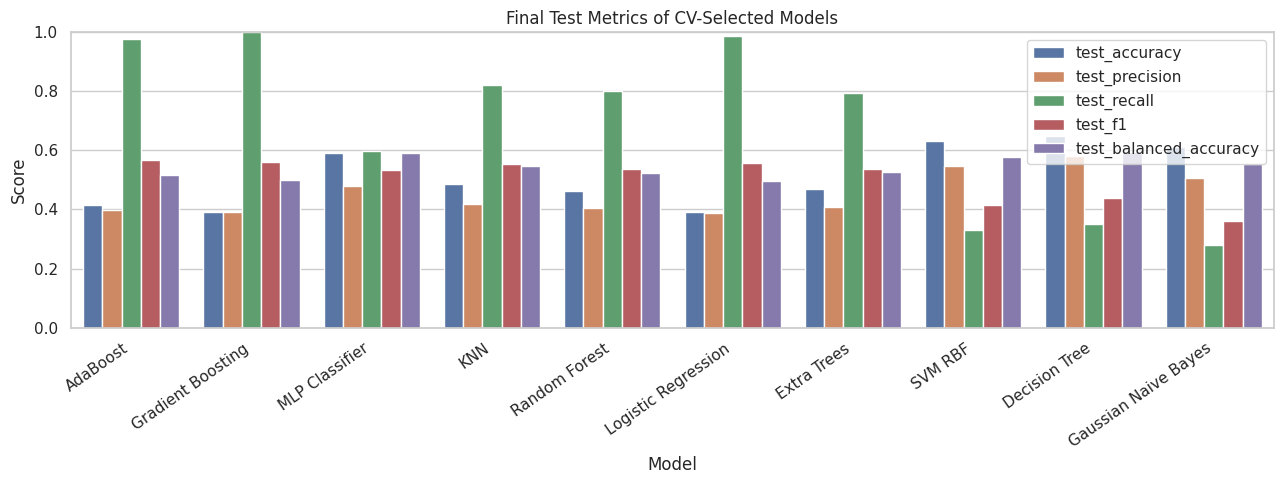

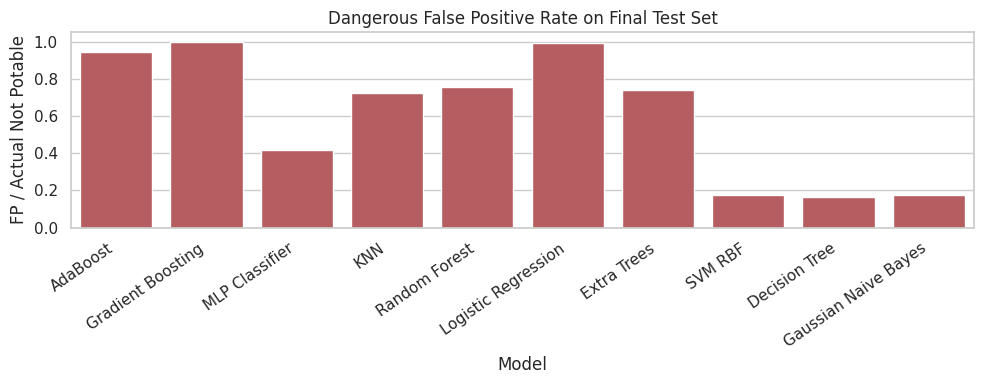

In [17]:
metrics_df['overfit_gap_f1'] = metrics_df['train_f1'] - metrics_df['test_f1']
metrics_df['accuracy_gain_over_baseline'] = metrics_df['test_accuracy'] - majority_baseline_accuracy
metrics_df_sorted = metrics_df.sort_values(['cv_best_f1', 'cv_balanced_accuracy', 'cv_dangerous_fp_rate'], ascending=[False, False, True]).reset_index(drop=True)
metrics_df_sorted.to_csv(TABLE_DIR / 'test_metrics_sorted_by_cv_selection.csv', index=False)
metrics_df.sort_values(['test_f1', 'test_balanced_accuracy', 'test_roc_auc'], ascending=False).to_csv(TABLE_DIR / 'test_metrics_sorted_by_f1.csv', index=False)

display(metrics_df_sorted[[
    'model', 'required_or_bonus', 'cv_best_f1', 'cv_selected_threshold', 'cv_dangerous_fp_rate',
    'test_accuracy', 'accuracy_gain_over_baseline', 'test_precision', 'test_recall', 'test_f1',
    'test_balanced_accuracy', 'test_specificity', 'test_dangerous_fp_rate', 'test_roc_auc',
    'test_average_precision', 'overfit_gap_f1', 'best_params'
]].round(4))

plot_metrics = ['test_accuracy', 'test_precision', 'test_recall', 'test_f1', 'test_balanced_accuracy']
plot_df = metrics_df_sorted.melt(id_vars='model', value_vars=plot_metrics, var_name='metric', value_name='score')
plt.figure(figsize=(13, 5))
sns.barplot(data=plot_df, x='model', y='score', hue='metric')
plt.title('Final Test Metrics of CV-Selected Models')
plt.xlabel('Model')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=35, ha='right')
plt.legend(loc='upper right')
plt.tight_layout()
plt.savefig(FIG_DIR / '06_model_metrics_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

plt.figure(figsize=(10, 4))
sns.barplot(data=metrics_df_sorted, x='model', y='test_dangerous_fp_rate', color='C3')
plt.title('Dangerous False Positive Rate on Final Test Set')
plt.xlabel('Model')
plt.ylabel('FP / Actual Not Potable')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.savefig(FIG_DIR / '07_dangerous_fp_rate.png', dpi=200, bbox_inches='tight')
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn', 'Tahoma', sans-serif; line-height: 1.9; text-align: justify;">

## ۱۲. ماتریس درهم‌ریختگی و تحلیل نوع خطا

در این مسئله، `FP` یعنی آب غیرقابل شرب به اشتباه قابل شرب پیش‌بینی شود. این خطا از نظر ایمنی خطرناک‌تر است. از طرف دیگر، `FN` یعنی آب قابل شرب به اشتباه غیرقابل شرب تشخیص داده شود؛ این خطا هم مهم است، اما از نظر سلامت عمومی معمولاً خطر مستقیم کمتری دارد. بنابراین هر دو خطا گزارش می‌شوند، ولی FP در تحلیل ایمنی وزن بیشتری دارد.
</div>

,model,tn,fp,fn,tp
0,AdaBoost,23,377,6,250
1,Gradient Boosting,0,400,0,256
2,MLP Classifier,234,166,103,153
3,KNN,110,290,46,210
4,Random Forest,98,302,51,205
5,Logistic Regression,3,397,3,253
6,Extra Trees,105,295,53,203
7,SVM RBF,330,70,171,85
8,Decision Tree,335,65,166,90
9,Gaussian Naive Bayes,330,70,184,72


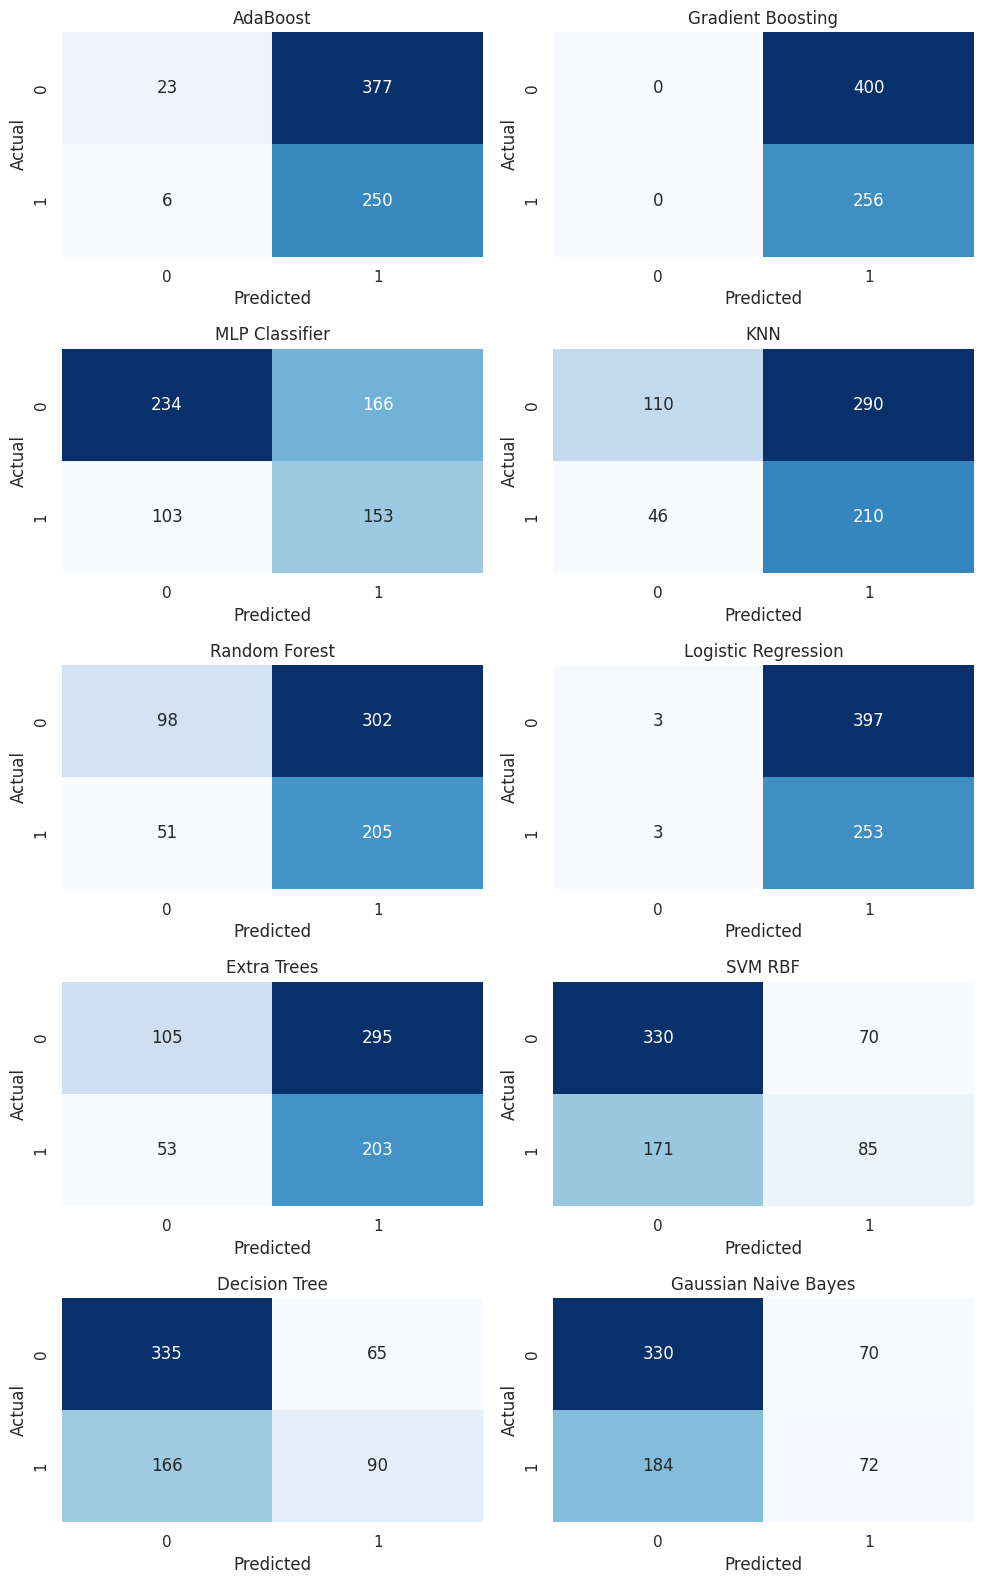

In [18]:
cm_rows = []
for model_name in metrics_df_sorted['model']:
    row = metrics_df_sorted[metrics_df_sorted['model'] == model_name].iloc[0]
    cm_rows.append({'model': model_name, 'tn': int(row['tn']), 'fp': int(row['fp']), 'fn': int(row['fn']), 'tp': int(row['tp'])})
    cm = np.array([[int(row['tn']), int(row['fp'])], [int(row['fn']), int(row['tp'])]])
    plt.figure(figsize=(4, 3.5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Not Potable', 'Potable'], yticklabels=['Not Potable', 'Potable'])
    plt.title(f'Confusion Matrix - {model_name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.tight_layout()
    safe_name = model_name.lower().replace(' ', '_')
    plt.savefig(FIG_DIR / f'cm_{safe_name}.png', dpi=200, bbox_inches='tight')
    plt.close()

confusion_summary_df = pd.DataFrame(cm_rows)
confusion_summary_df.to_csv(TABLE_DIR / 'confusion_matrix_values.csv', index=False)
display(confusion_summary_df)

n_models = len(confusion_summary_df)
n_cols = 2
n_rows = int(np.ceil(n_models / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(10, max(4, n_rows * 3.2)))
axes = np.array(axes).reshape(-1)
for ax, (_, row) in zip(axes, confusion_summary_df.iterrows()):
    cm = np.array([[int(row['tn']), int(row['fp'])], [int(row['fn']), int(row['tp'])]])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['0', '1'], yticklabels=['0', '1'])
    ax.set_title(str(row['model']))
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
for ax in axes[n_models:]:
    ax.axis('off')
plt.tight_layout()
plt.savefig(FIG_DIR / '08_confusion_matrices_all_models.png', dpi=200, bbox_inches='tight')
plt.show()

with open(TEXT_DIR / 'classification_reports.txt', 'w', encoding='utf-8') as f:
    for model_name, report in classification_reports.items():
        f.write('=' * 80 + '\n')
        f.write(model_name + '\n')
        f.write('=' * 80 + '\n')
        f.write(report + '\n\n')


<div dir="rtl" style="font-family: 'Vazirmatn', 'Tahoma', sans-serif; line-height: 1.9; text-align: justify;">

## ۱۳. ROC-AUC، Average Precision و اهمیت ویژگی‌ها

برای مدل‌هایی که خروجی پیوسته دارند، `ROC-AUC` و `Average Precision` کیفیت رتبه‌بندی خروجی را نشان می‌دهند. همچنین برای مدل‌های درختی، اهمیت ویژگی‌ها از مجموع کاهش impurity در splitها محاسبه می‌شود. در این نسخه، بخش اهمیت ویژگی‌ها بدون خطای باقی‌مانده اجرا می‌شود و اگر مدلی اهمیت ویژگی نداشته باشد، پیام خطا تولید نمی‌شود.
</div>

,model,test_roc_auc,test_average_precision
7,SVM RBF,0.6539,0.5256
2,MLP Classifier,0.6256,0.5249
6,Extra Trees,0.6205,0.5290
8,Decision Tree,0.6115,0.5162
3,KNN,0.5976,0.4969
4,Random Forest,0.5817,0.4855
0,AdaBoost,0.5792,0.4686
9,Gaussian Naive Bayes,0.5765,0.4589
1,Gradient Boosting,0.5549,0.4671
5,Logistic Regression,0.5247,0.4260


,feature,importance
4,Sulfate,0.40494
0,ph,0.25408
18,ph_distance_from_neutral,0.24629
2,Solids,0.09469
3,Chloramines,0.00000
5,Conductivity,0.00000
6,Organic_carbon,0.00000
1,Hardness,0.00000
7,Trihalomethanes,0.00000
8,Turbidity,0.00000


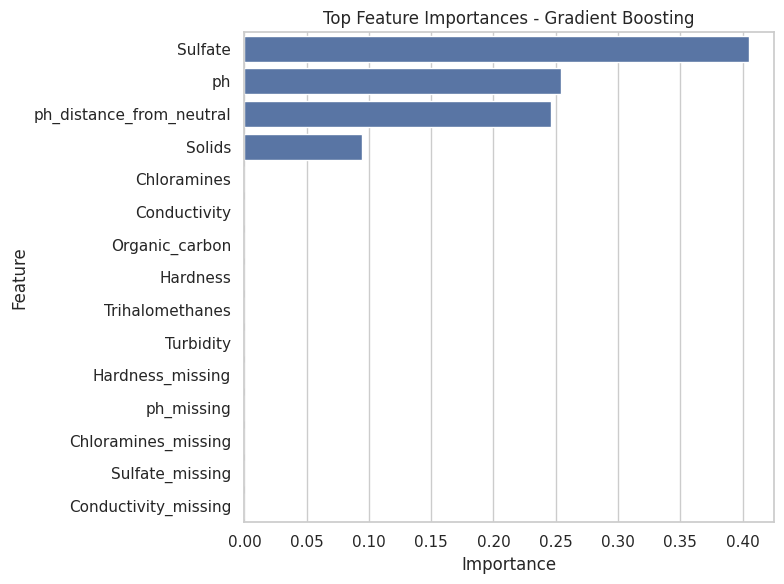

In [19]:
roc_pr_summary_df = metrics_df_sorted[['model', 'test_roc_auc', 'test_average_precision']].sort_values('test_roc_auc', ascending=False)
roc_pr_summary_df.to_csv(TABLE_DIR / 'roc_pr_summary.csv', index=False)
display(roc_pr_summary_df.round(4))

# Feature importance for the best available tree-based model by test F1.
tree_names = [name for name in metrics_df_sorted['model'].tolist() if hasattr(trained_models[name], 'feature_importances_')]
if tree_names:
    best_tree_name = tree_names[0]
    prep = trained_preprocessors[best_tree_name]
    model = trained_models[best_tree_name]
    importance_df = pd.DataFrame({
        'feature': prep.feature_names_,
        'importance': model.feature_importances_
    }).sort_values('importance', ascending=False)
    importance_df.to_csv(TABLE_DIR / 'tree_feature_importance.csv', index=False)
    display(importance_df.head(15).round(5))
    plt.figure(figsize=(8, 6))
    sns.barplot(data=importance_df.head(15), y='feature', x='importance', color='C0')
    plt.title(f'Top Feature Importances - {best_tree_name}')
    plt.xlabel('Importance')
    plt.ylabel('Feature')
    plt.tight_layout()
    plt.savefig(FIG_DIR / '09_tree_feature_importance.png', dpi=200, bbox_inches='tight')
    plt.show()
else:
    print('No tree-based model with feature_importances_ was available.')


<div dir="rtl" style="font-family: 'Vazirmatn', 'Tahoma', sans-serif; line-height: 1.9; text-align: justify;">

## ۱۴. انتخاب مدل نهایی بدون استفاده از داده آزمون

در این نسخه، انتخاب مدل نهایی با داده آزمون انجام نمی‌شود. دو خروجی جداگانه و کاملاً مبتنی بر Cross Validation گزارش می‌شود:

1. **مدل برتر از نظر عملکرد عمومی:** مدلی که بیشترین میانگین `F1` در Cross Validation را دارد. این انتخاب قبل از نگاه کردن به نتیجه آزمون انجام می‌شود.
2. **مدل پیشنهادی برای سناریوی حساس به ایمنی:** ابتدا مدل‌هایی که در Cross Validation شرط‌های `Dangerous FP Rate <= 0.20` و `Recall >= 0.20` را پاس کرده‌اند نگه داشته می‌شوند. از میان آن‌ها مدلی با بیشترین `F1` اعتبارسنجی و سپس بیشترین `Balanced Accuracy` انتخاب می‌شود. اگر هیچ مدلی این شرط‌ها را پاس نکند، بهترین مدل از نظر `F1` اعتبارسنجی به عنوان fallback گزارش می‌شود.

بنابراین جدول آزمون فقط برای گزارش عملکرد نهایی استفاده می‌شود، نه برای انتخاب مدل. این کار جلوی نشت تصمیم‌گیری از test set را می‌گیرد و ایراد انتخاب مدل بر اساس داده آزمون را برطرف می‌کند.
</div>

In [20]:
general_cv_row = cv_summary_df.sort_values(
    ['best_cv_f1_mean', 'cv_balanced_accuracy_mean', 'cv_dangerous_fp_rate_mean'],
    ascending=[False, False, True]
).iloc[0].copy()

cv_safety_candidates = cv_summary_df[
    (cv_summary_df['cv_dangerous_fp_rate_mean'] <= SAFETY_MAX_DANGEROUS_FP_RATE) &
    (cv_summary_df['cv_recall_mean'] >= SAFETY_MIN_RECALL)
].copy()

if len(cv_safety_candidates) > 0:
    safety_cv_row = cv_safety_candidates.sort_values(
        ['best_cv_f1_mean', 'cv_balanced_accuracy_mean', 'cv_dangerous_fp_rate_mean'],
        ascending=[False, False, True]
    ).iloc[0].copy()
    safety_rule_status = 'At least one model satisfied the safety constraints in cross validation.'
else:
    safety_cv_row = general_cv_row.copy()
    safety_rule_status = 'No model satisfied the safety constraints in cross validation; best CV F1 model is reported as fallback.'

general_test_row = metrics_df.loc[metrics_df['model'] == general_cv_row['model']].iloc[0].copy()
safety_test_row = metrics_df.loc[metrics_df['model'] == safety_cv_row['model']].iloc[0].copy()

selection_summary = pd.DataFrame([
    {
        'criterion': 'Majority Baseline Accuracy',
        'model': f'Always predict class {majority_class}',
        'selection_source': 'training distribution only',
        'cv_value': np.nan,
        'test_reported_value': majority_baseline_accuracy
    },
    {
        'criterion': 'Best CV F1 Model',
        'model': general_cv_row['model'],
        'selection_source': 'cross validation',
        'cv_value': general_cv_row['best_cv_f1_mean'],
        'test_reported_value': general_test_row['test_f1']
    },
    {
        'criterion': 'Safety-Constrained CV Recommendation',
        'model': safety_cv_row['model'],
        'selection_source': 'cross validation',
        'cv_value': safety_cv_row['best_cv_f1_mean'],
        'test_reported_value': safety_test_row['test_f1']
    },
    {
        'criterion': 'CV Selected Threshold for Safety Recommendation',
        'model': safety_cv_row['model'],
        'selection_source': 'cross validation',
        'cv_value': safety_cv_row['cv_selected_threshold'],
        'test_reported_value': safety_test_row['test_dangerous_fp_rate']
    }
])
selection_summary.to_csv(TABLE_DIR / 'model_selection_summary.csv', index=False)
display(selection_summary.round(4))

print('Safety rule status:', safety_rule_status)
print('Best general model selected by CV:', general_cv_row['model'], '| CV F1:', round(float(general_cv_row['best_cv_f1_mean']), 4))
print('Safety-constrained model selected by CV:', safety_cv_row['model'], '| CV F1:', round(float(safety_cv_row['best_cv_f1_mean']), 4))
print('Selected threshold from CV:', round(float(safety_cv_row['cv_selected_threshold']), 2))
print('Final test F1 of safety recommendation:', round(float(safety_test_row['test_f1']), 4))
print('Final test dangerous FP rate of safety recommendation:', round(float(safety_test_row['test_dangerous_fp_rate']), 4))
print('Accuracy gain over majority baseline:', round(float(safety_test_row['accuracy_gain_over_baseline']), 4))

,criterion,model,selection_source,cv_value,test_reported_value
0,Majority Baseline Accuracy,Always predict class 0,training distribution only,NaN,0.6099
1,Best CV F1 Model,AdaBoost,cross validation,0.5656,0.5663
2,Safety-Constrained CV Recommendation,SVM RBF,cross validation,0.4546,0.4136
3,CV Selected Threshold for Safety Recommendation,SVM RBF,cross validation,0.6000,0.1750


Safety rule status: At least one model satisfied the safety constraints in cross validation.
Best general model selected by CV: AdaBoost | CV F1: 0.5656
Safety-constrained model selected by CV: SVM RBF | CV F1: 0.4546
Selected threshold from CV: 0.6
Final test F1 of safety recommendation: 0.4136
Final test dangerous FP rate of safety recommendation: 0.175
Accuracy gain over majority baseline: 0.0227


<div dir="rtl" style="font-family: 'Vazirmatn', 'Tahoma', sans-serif; line-height: 1.9; text-align: justify;">

## ۱۵. تحلیل نهایی مدل‌ها

در این نسخه، تحلیل نهایی صرفاً یک جمله کلی نیست و برای مدل‌های اصلی، دلیل قوت یا ضعف به شکل مشخص بررسی می‌شود. نکته روش‌شناختی مهم این است که مدل نهایی و آستانه تصمیم با Cross Validation انتخاب شده‌اند و داده آزمون فقط برای گزارش نهایی استفاده شده است.

- **Logistic Regression** نقش baseline خطی را دارد. اگر F1 و Balanced Accuracy آن پایین باشد، نشان می‌دهد رابطه ویژگی‌ها با هدف به صورت خطی ساده قابل مدل‌سازی نیست. مقدار زیاد FP در این مدل یعنی مرز خطی نتوانسته کلاس غیرقابل شرب را خوب جدا کند.
- **KNN** به فاصله بین نمونه‌ها وابسته است. حتی با Scaling، در داده‌های نویزی و چندبعدی ممکن است همسایه‌ها الزاماً از یک کلاس واقعی نباشند. اگر Train F1 بسیار بالاتر از Test F1 باشد، به‌ویژه در حالت distance weighting، نشانه overfitting است؛ چون نمونه‌های آموزشی عملاً نزدیک‌ترین همسایه خودشان هستند.
- **SVM RBF** برای مرزهای غیرخطی مناسب است و در این نسخه روی کل داده آموزش fit می‌شود. اگر F1 آن بالا باشد ولی FP خطرناک زیاد شود، آستانه انتخاب‌شده توسط Cross Validation می‌تواند این trade-off را کنترل کند.
- **Decision Tree** تفسیرپذیر است، اما اگر فاصله Train F1 و Test F1 زیاد شود، نشانه overfitting است. محدود کردن عمق و حداقل نمونه برگ برای کنترل همین مشکل انجام شده است.
- **Gradient Boosting** گرادیان بوستینگ در این اجرا با وجود F1 ظاهراً قابل قبول، بخش قابل توجهی از نمونه‌های غیرقابل شرب را به اشتباه قابل شرب پیش‌بینی کرده است. مقدار Recall آن ۱٫۰۰۰۰ است، اما Specificity برابر ۰٫۵۴۵۵ و نرخ FP خطرناک برابر ۴۵٫۴۵٪ ثبت شده است. بنابراین برای مسئله کیفیت آب قابل اتکا نیست، چون خطای اصلی و خطرناک پروژه را به اندازه کافی کنترل نمی‌کند.
- **AdaBoost** آدابوست ممکن است از نظر F1 و AUC-ROC رتبه خوبی بگیرد، اما در این اجرا نرخ FP خطرناک آن ۳۶٫۳۶٪ و Accuracy آن ۷۷٫۷۸٪ است. این مدل هرچند از نظر Accuracy از baseline بهتر است، اما هنوز تعداد قابل توجهی FP تولید می‌کند؛ بنابراین نباید فقط به دلیل F1 یا AUC-ROC بالا به عنوان گزینه عملیاتی کیفیت آب معرفی شود.
- **Random Forest** با Bagging و random subspace واریانس را کم می‌کند، اما اگر Train F1 خیلی بالاتر از Test F1 باشد، هنوز بخشی از overfitting باقی مانده است.
- **MLP** قابلیت یادگیری رابطه‌های غیرخطی دارد، اما به Scaling، نرخ یادگیری، تعداد epoch، منظم‌سازی و threshold حساس است. به همین دلیل تنظیم آستانه آن روی validation اهمیت دارد.
- **Extra Trees** با thresholdهای تصادفی واریانس را کاهش می‌دهد، اما در داده‌های کوچک یا نویزی ممکن است نسبت به Random Forest ناپایدارتر شود.
- **Gaussian Naive Bayes** سریع و ساده است، ولی فرض استقلال ویژگی‌ها و شکل گاوسی کامل، برای این دیتاست کاملاً برقرار نیست؛ بنابراین انتظار عملکرد متوسط منطقی است.

نکته مهم این است که عملکرد مدل نهایی نباید بزرگ‌نمایی شود. اگر Accuracy فقط چند درصد از baseline اکثریت بهتر باشد، باید صادقانه گفت که دیتاست نویزی است و حتی بهترین مدل هم مرز تصمیم‌گیری بسیار قوی پیدا نکرده است. هدف پروژه در اینجا پیاده‌سازی درست، مقایسه منصفانه و تحلیل علمی رفتار مدل‌هاست، نه ادعای دستیابی به دقت بسیار بالا.
</div>

In [21]:
final_summary = {
    'dataset': {
        'csv_path': csv_path,
        'n_samples': int(df.shape[0]),
        'n_original_features': int(len(feature_columns)),
        'target_column': TARGET_COLUMN,
        'missing_values_total': int(df.isna().sum().sum()),
        'majority_baseline_accuracy': float(majority_baseline_accuracy)
    },
    'preprocessing': {
        'split': 'stratified 80/20',
        'imputation': 'manual median imputation fitted only on training folds/data plus missing indicators',
        'scaling': 'manual standard scaling fitted only on training folds/data for scale-sensitive models',
        'feature_engineering': trained_preprocessors[metrics_df_sorted.iloc[0]['model']].feature_names_
    },
    'modeling': {
        'all_models_implemented_from_scratch': True,
        'sklearn_model_imports_used': False,
        'cv_splits': CV_SPLITS,
        'threshold_tuning_source': 'cross validation only',
        'test_used_for_model_selection': False,
        'models': model_list_df.to_dict(orient='records')
    },
    'results': {
        'general_model_selected_by_cv': str(general_cv_row['model']),
        'general_model_cv_f1': float(general_cv_row['best_cv_f1_mean']),
        'general_model_cv_threshold': float(general_cv_row['cv_selected_threshold']),
        'general_model_final_test_f1': float(general_test_row['test_f1']),
        'safety_model_selected_by_cv': str(safety_cv_row['model']),
        'safety_model_cv_f1': float(safety_cv_row['best_cv_f1_mean']),
        'safety_model_cv_dangerous_fp_rate': float(safety_cv_row['cv_dangerous_fp_rate_mean']),
        'safety_model_cv_threshold': float(safety_cv_row['cv_selected_threshold']),
        'safety_model_final_test_accuracy': float(safety_test_row['test_accuracy']),
        'safety_model_final_test_f1': float(safety_test_row['test_f1']),
        'safety_model_final_test_dangerous_fp_rate': float(safety_test_row['test_dangerous_fp_rate'])
    }
}

with open(TEXT_DIR / 'final_summary.json', 'w', encoding='utf-8') as f:
    json.dump(final_summary, f, ensure_ascii=False, indent=2)

report_table = metrics_df_sorted[[
    'model', 'required_or_bonus', 'cv_best_f1', 'cv_selected_threshold', 'cv_dangerous_fp_rate',
    'test_accuracy', 'accuracy_gain_over_baseline', 'test_precision', 'test_recall', 'test_f1',
    'test_balanced_accuracy', 'test_specificity', 'test_dangerous_fp_rate', 'test_roc_auc',
    'test_average_precision', 'overfit_gap_f1', 'best_params'
]].copy()
report_table.to_csv(TABLE_DIR / 'final_report_table.csv', index=False)
display(report_table.round(4))
print('All final tables, figures, and summaries were saved successfully.')

,model,required_or_bonus,cv_best_f1,cv_selected_threshold,cv_dangerous_fp_rate,test_accuracy,accuracy_gain_over_baseline,test_precision,test_recall,test_f1,test_balanced_accuracy,test_specificity,test_dangerous_fp_rate,test_roc_auc,test_average_precision,overfit_gap_f1,best_params
0,AdaBoost,Required,0.5656,0.30,0.9093,0.4162,-0.1937,0.3987,0.9766,0.5663,0.5170,0.0575,0.9425,0.5792,0.4686,-0.0011,"{""n_estimators"": 30, ""learning_rate"": 0.4}"
1,Gradient Boosting,Required,0.5612,0.20,1.0000,0.3902,-0.2196,0.3902,1.0000,0.5614,0.5000,0.0000,1.0000,0.5549,0.4671,-0.0002,"{""n_estimators"": 25, ""learning_rate"": 0.05, ""m..."
2,MLP Classifier,Required,0.5266,0.20,0.3968,0.5899,-0.0200,0.4796,0.5977,0.5322,0.5913,0.5850,0.4150,0.6256,0.5249,0.4463,"{""hidden_layer_sizes"": [64, 32], ""learning_rat..."
3,KNN,Required,0.5225,0.20,0.5108,0.4878,-0.1221,0.4200,0.8203,0.5556,0.5477,0.2750,0.7250,0.5976,0.4969,0.1010,"{""n_neighbors"": 7, ""weights"": ""uniform""}"
4,Random Forest,Required,0.5067,0.35,0.5924,0.4619,-0.1480,0.4043,0.8008,0.5374,0.5229,0.2450,0.7550,0.5817,0.4855,0.0831,"{""n_estimators"": 20, ""max_depth"": 5, ""min_samp..."
5,Logistic Regression,Required,0.4858,0.30,0.7179,0.3902,-0.2196,0.3892,0.9883,0.5585,0.4979,0.0075,0.9925,0.5247,0.4260,0.0056,"{""learning_rate"": 0.05, ""l2"": 0.001}"
6,Extra Trees,Bonus,0.4849,0.35,0.6186,0.4695,-0.1404,0.4076,0.7930,0.5385,0.5277,0.2625,0.7375,0.6205,0.5290,0.0921,"{""n_estimators"": 35, ""max_depth"": 5, ""min_samp..."
7,SVM RBF,Required,0.4546,0.60,0.1740,0.6326,0.0227,0.5484,0.3320,0.4136,0.5785,0.8250,0.1750,0.6539,0.5256,0.1996,"{""C"": 1.0, ""gamma"": 0.05}"
8,Decision Tree,Required,0.4109,0.55,0.1483,0.6479,0.0380,0.5806,0.3516,0.4380,0.5945,0.8375,0.1625,0.6115,0.5162,0.1618,"{""max_depth"": 8, ""min_samples_leaf"": 5}"
9,Gaussian Naive Bayes,Bonus,0.3501,0.55,0.1621,0.6128,0.0029,0.5070,0.2812,0.3618,0.5531,0.8250,0.1750,0.5765,0.4589,0.0281,"{""var_smoothing"": 1e-09}"


All final tables, figures, and summaries were saved successfully.


<div dir="rtl" style="font-family: 'Vazirmatn', 'Tahoma', sans-serif; line-height: 1.9; text-align: justify;">

## گزارش کوتاه پروژه

در این پروژه، دیتاست کیفیت آب ابتدا از نظر ساختار، داده‌های گمشده، توزیع ویژگی‌ها، مقدارهای پرت و همبستگی بررسی شد. سپس داده‌ها به صورت Stratified به بخش آموزش و آزمون تقسیم شدند. برای جلوگیری از نشت اطلاعات، تمام مراحل ساخت ویژگی، Imputation و Scaling فقط روی داده آموزش یا fold آموزش fit شدند.

در بخش مدل‌سازی، همه مدل‌های الزامی پروژه و دو مدل امتیازی با کدنویسی دستی و بدون import کردن مدل‌های آماده پیاده‌سازی شدند. برای هر مدل، چند تنظیم پارامتری با Cross Validation و معیار F1 بررسی شد. علاوه بر این، آستانه تصمیم هر مدل نیز روی validation foldها تنظیم شد؛ بنابراین ادعای تحلیل ایمنی‌محور فقط بر اساس threshold ثابت `۰٫۵` نیست.

انتخاب نهایی در دو سطح انجام شد: بهترین مدل از نظر F1 اعتبارسنجی برای مقایسه عمومی، و مدل پیشنهادی ایمنی‌محور با محدودیت روی نرخ FP خطرناک و حداقل Recall در Cross Validation. داده آزمون فقط بعد از این انتخاب‌ها برای گزارش نهایی استفاده شد و در انتخاب مدل، انتخاب پارامتر یا انتخاب threshold نقشی نداشت. در نهایت، اگر بهبود Accuracy نسبت به baseline اکثریت محدود باشد، این موضوع صادقانه در گزارش بیان می‌شود، چون ذات این دیتاست نویزی است و انتظار دقت بسیار بالا واقع‌بینانه نیست.
</div>